<img src=../figures/Brown_logo.svg width=50%>

# Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 28

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor


In [1]:
# Basic plotting tools needed in Python.
import json, re
import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
import sympy as sp # symbolic mathematics (only to check our derivatives)
import torch # PyTorch, for its automatic differentiation
from IPython.display import HTML

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides
torch.set_default_dtype(torch.float64) # double precision, as numpy

# Outline for today's lecture

The optimizers of Lectures 26 and 27 need the gradient of the objective, and in Lecture 26 L-BFGS-B paid $D_x$ extra evaluations of $f$ for each gradient. A model can have millions of parameters. Today: how to compute a gradient.

* By hand: the chain rule, on logistic regression (Lecture 24)
* Finite differences: easy to write, expensive and inexact
* Automatic differentiation: a graph of elementary operations, the forward mode and the reverse mode
* Backpropagation is the reverse mode, applied to the loss
* Which optimizer, when? A small benchmark

**References:**
* Section 13.3 of Murphy's book (backpropagation)
* A. G. Baydin, B. A. Pearlmutter, A. A. Radul & J. M. Siskind, *Automatic differentiation in machine learning: a survey*, Journal of Machine Learning Research 18, 2018.

In [2]:
# @title Figure code: the graphs of this lecture (logistic regression, and the DAG of f with its gradient paths)
# Hidden. One helper draws a graph: circles for the nodes, arrows for the edges, and colored paths drawn on top.
from matplotlib.patches import FancyArrowPatch, Circle

def draw_graph(ax, pos, edges, labels, paths=(), curved=None, r=0.32, fs=15):
    """pos: {node: (x, y)}; edges: [(a, b)]; paths: [(list of edges, color)], drawn thick under the arrows;
    curved: {edge: rad} for the arcs."""
    curved = curved or {}
    for k, (path, color) in enumerate(paths):                       # colored gradient paths, slightly offset
        for (a, b) in path:
            (x0, y0), (x1, y1) = pos[a], pos[b]
            off = 0.09 * (k - (len(paths) - 1) / 2)
            ax.add_patch(FancyArrowPatch((x0, y0 + off), (x1, y1 + off), connectionstyle=f"arc3,rad={curved.get((a, b), 0)}",
                                         arrowstyle="-", lw=7, color=color, alpha=0.75, shrinkA=14, shrinkB=14, zorder=1))
    for (a, b) in edges:
        ax.add_patch(FancyArrowPatch(pos[a], pos[b], connectionstyle=f"arc3,rad={curved.get((a, b), 0)}",
                                     arrowstyle="-|>", mutation_scale=16, lw=1.4, color="k", shrinkA=22, shrinkB=22, zorder=2))
    for n, (x, y) in pos.items():
        ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.5, zorder=3))
        ax.text(x, y, labels.get(n, n), ha="center", va="center", fontsize=fs, zorder=4)
    ax.set_aspect("equal"); ax.axis("off")
    xs, ys = zip(*pos.values())
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8); ax.set_ylim(min(ys) - 0.9, max(ys) + 0.9)

# logistic regression as a computational graph (the first example): the weights are leaves, like the data;
# each arrow on the way from the loss back to the weights is colored by its factor in the chain rule
_lpos = {"one": (0, 1.65), "x": (0, 0.75), "w0": (0, -0.35), "w1": (0, -1.25), "a": (2.4, 0.2), "r": (4.8, 0.2),
         "L": (7.2, 0.2), "y": (7.2, 1.75)}
_llab = {"one": "$1$", "x": "$x_n$", "w0": "$w_0$", "w1": "$w_1$", "a": "$a_n$", "r": r"$\rho_n$", "L": r"$\mathrm{NLL}_n$", "y": "$y_n$"}
fig_logreg, ax = plt.subplots(figsize=(9, 3.6))
for path, color in [([("w0", "a"), ("w1", "a")], "brown"), ([("a", "r")], "teal"), ([("r", "L")], "purple")]:
    for (p, q) in path:
        ax.plot(*zip(_lpos[p], _lpos[q]), color=color, lw=7, alpha=0.75, solid_capstyle="butt", zorder=1)
draw_graph(ax, _lpos, [("one", "a"), ("x", "a"), ("w0", "a"), ("w1", "a"), ("a", "r"), ("r", "L"), ("y", "L")], _llab, fs=13, r=0.38)
[t.set_fontsize(10) for t in ax.texts if t.get_text() == _llab["L"]]
for (x, y), t, ha in [((-0.55, 1.2), "basis functions\nof the data", "right"), ((-0.55, -0.8), "weights", "right"),
                      ((7.7, 1.75), "data", "left"), ((4.8, 0.75), "prediction", "center")]:
    ax.text(x, y, t, ha=ha, va="center", fontsize=11, color="#555", style="italic")   # what is given, what is computed
for x, t in [(2.4, "linear model\n" + r"$a_n=w_0 \cdot 1 + w_1 x_n$"), (4.8, "sigmoid\n" + r"$\rho_n=\sigma(a_n)$"), (7.2, "binary\ncross entropy")]:
    ax.text(x, -1.0, t, ha="center", va="top", fontsize=11, color="#555")
ax.set_xlim(-2.4, 8.4); ax.set_ylim(-2.0, 2.4)
plt.close(fig_logreg)

# the DAG of f(x1, x2) = x2 exp(x1) sqrt(x1 + x2 exp(x1)), as in the notes
DAG_POS = {1: (0, 0), 2: (0, -2), 3: (1.6, 0.75), 4: (3.2, 0), 5: (4.8, 0), 6: (6.4, 0), 7: (8.0, 0)}
DAG_EDGES = [(1, 3), (1, 5), (2, 4), (3, 4), (4, 5), (4, 7), (5, 6), (6, 7)]
DAG_CURVED = {(1, 5): -0.6, (4, 7): 0.6}
_dlab = {k: f"$f_{k}$" for k in DAG_POS}

DAG_EXPR = {3: ("$= e^{f_1}$", 0.15, -0.62), 4: ("$= f_2\\,f_3$", 0.1, 0.62), 5: ("$= f_1 + f_4$", 0, -0.62),
            6: ("$= \\sqrt{f_5}$", 0, 0.62), 7: ("$= f_4\\,f_6$", 0, 0.62)}

def fig_dag(paths=(), title=None, expr=False):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    draw_graph(ax, DAG_POS, DAG_EDGES, _dlab, paths=paths, curved=DAG_CURVED)
    ax.text(-0.55, 0, "$x_1$ =", ha="right", va="center", fontsize=14); ax.text(-0.55, -2, "$x_2$ =", ha="right", va="center", fontsize=14)
    ax.text(8.55, 0, "= $f$", ha="left", va="center", fontsize=14); ax.set_xlim(-1.6, 9.4)
    if expr:                                                     # what each node computes, next to it
        for k, (t, dx, dy) in DAG_EXPR.items():
            x, y = DAG_POS[k]
            ax.text(x + dx, y + dy, t, ha="center", va="center", fontsize=14, color="#333",
                    bbox=dict(fc="white", ec="none", pad=1))
    if title: ax.set_title(title, fontsize=13)
    plt.close(fig)
    return fig

fig_dag_plain = fig_dag(expr=True)
fig_paths_4 = fig_dag([([(4, 5), (5, 6), (6, 7)], "purple"), ([(4, 7)], "teal")],
                      r"$\partial f_7/\partial f_4$: two paths from $f_4$ to $f_7$")
fig_paths_1 = fig_dag([([(1, 5), (5, 6), (6, 7)], "purple"), ([(1, 3), (3, 4), (4, 5), (5, 6), (6, 7)], "brown"),
                       ([(1, 3), (3, 4), (4, 7)], "teal")], r"$\partial f_7/\partial f_1$: three paths from $f_1$ to $f_7$")

## A gradient we already know: logistic regression

In Lecture 24 we fitted logistic regression by minimizing its NLL, the binary cross entropy, with a gradient-based optimizer. The key results:

$$
\rho_n = \sigma(a_n), \quad a_n = \mathbf{w}^T\boldsymbol{\phi}(\mathbf{x}_n), \qquad
\text{NLL}(\mathbf{w}) = -\sum_{n=1}^N \left[y_n\log \rho_n + (1-y_n)\log(1-\rho_n)\right]
$$

$$
\nabla_{\mathbf{w}}\text{NLL}(\mathbf{w}) = \sum_{n=1}^N \boldsymbol{\phi}(\mathbf{x}_n)\left(\rho_n-y_n\right) = \boldsymbol{\Phi}^T\left(\boldsymbol{\rho}-\mathbf{y}\right)
$$

We found this gradient **by hand**, with the chain rule. Let us look at that calculation again, as a chain of simple functions.

### Where that gradient came from: the chain rule

Each data point goes through three simple functions: the linear model, the sigmoid, and the cross entropy. Follow a weight $w_d$ from the loss back to it, one arrow at a time:

$$
\frac{\partial\,\text{NLL}}{\partial w_d} = \sum_{n=1}^{N}
{\color{purple}{\frac{\partial\, \text{NLL}_n}{\partial \rho_n}}}\;
{\color{teal}{\frac{\partial \rho_n}{\partial a_n}}}\;
{\color{brown}{\frac{\partial a_n}{\partial w_d}}},
\qquad \text{NLL}_n = -\left[y_n\log \rho_n + (1-y_n)\log(1-\rho_n)\right]
$$

The colored arrows are the only ones the chain rule visits: no path goes to $1$ or $x_n$, because we do not need derivatives with respect to the data.

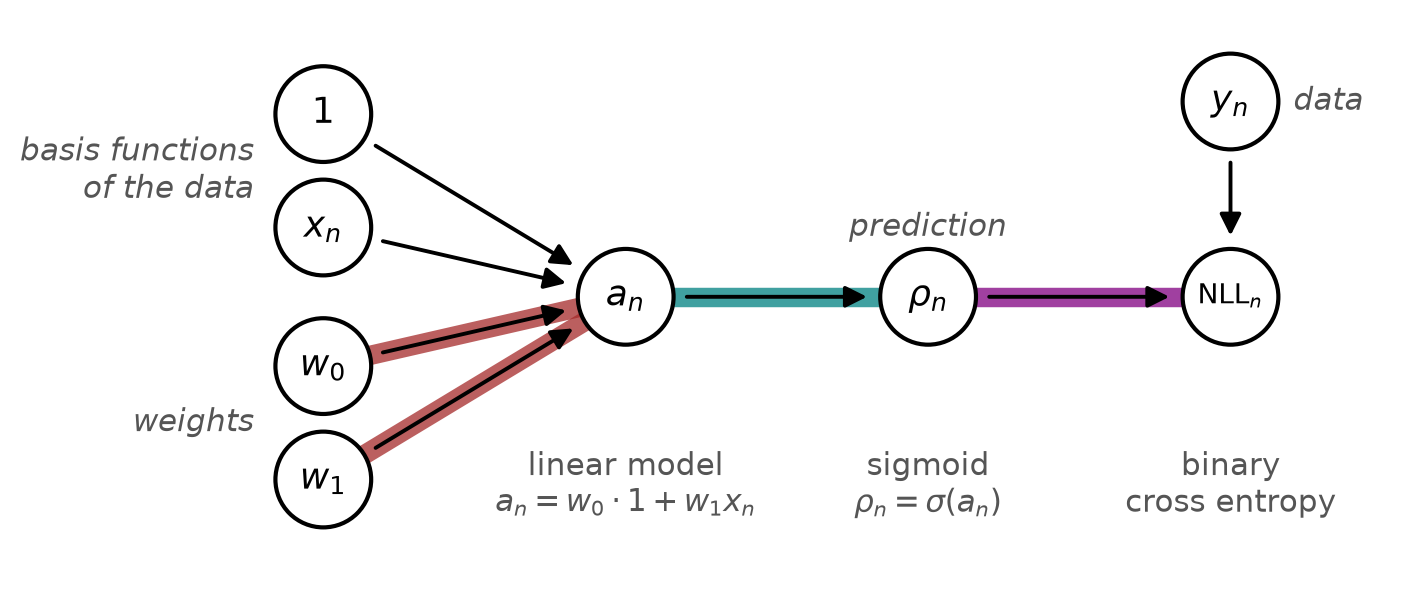

In [3]:
fig_logreg

* ${\color{purple}{\partial\, \text{NLL}_n/\partial \rho_n = -\frac{y_n}{\rho_n} + \frac{1-y_n}{1-\rho_n} = \frac{\rho_n - y_n}{\rho_n(1-\rho_n)}}}$ (the cross entropy)

* ${\color{teal}{\partial \rho_n/\partial a_n = \rho_n(1-\rho_n)}}$ (the derivative of the sigmoid, Lecture 23)

* ${\color{brown}{\partial a_n/\partial w_d = \phi_d(\mathbf{x}_n)}}$ (the linear model)

$$
\frac{\partial\,\text{NLL}}{\partial w_d} = \sum_{n=1}^{N} {\color{purple}{\frac{\rho_n - y_n}{\rho_n(1-\rho_n)}}}\; {\color{teal}{\rho_n(1-\rho_n)}}\; {\color{brown}{\phi_d(\mathbf{x}_n)}} = \sum_{n=1}^{N} \left(\rho_n - y_n\right)\phi_d(\mathbf{x}_n)
$$

the result of Lecture 24. The purple and teal factors do not depend on $d$: they are the same for **every** weight. **Computed once, reused** for all $M$ weights, and only the brown factor changes. Keep this in mind.

#### Note: the same calculation as in Lecture 24, grouped differently

In Lecture 24 we differentiated the two logarithms first, $\nabla_{\mathbf{w}}\log\rho_n = \frac{1}{\rho_n}\nabla_{\mathbf{w}}\rho_n$ and $\nabla_{\mathbf{w}}\log(1-\rho_n) = -\frac{1}{1-\rho_n}\nabla_{\mathbf{w}}\rho_n$, with $\nabla_{\mathbf{w}}\rho_n = \rho_n(1-\rho_n)\boldsymbol{\phi}(\mathbf{x}_n)$. That last term is the teal factor times the brown one; the two fractions together are the purple factor. The chain is the same, only the grouping of the factors differs.

Two details:
* **The cancellation.** The $\rho_n(1-\rho_n)$ of the sigmoid cancels against the denominator of the cross entropy, leaving the residual $\rho_n - y_n$. This is not a coincidence: the cross entropy is the NLL of the Bernoulli distribution, and the sigmoid is its natural link. The same happens for linear regression: the NLL of a Gaussian with a linear model gives the residual $\hat{y}_n - y_n$ times $\boldsymbol{\phi}(\mathbf{x}_n)$.
* **Where the sum goes.** Every factor depends on the data point $n$ (through $\rho_n$, $y_n$ and $\mathbf{x}_n$), so the sum over the data wraps the whole product, not only the first factor.

The code at the end of this lecture checks $\boldsymbol{\Phi}^T(\boldsymbol{\rho}-\mathbf{y})$ against PyTorch.

## Four ways to compute a derivative

1. **By hand**, as we just did: exact, but slow and error-prone, and it must be redone for every new model.
2. **Finite differences**: $\frac{\partial f}{\partial x_i} \approx \frac{f(\mathbf{x} + h\mathbf{e}_i) - f(\mathbf{x})}{h}$. Works on any black box (a simulation), but costs $D_x + 1$ evaluations of $f$ per gradient, and is inexact.
3. **Symbolic differentiation** (e.g. `sympy`): an exact formula, but it grows quickly, and repeats the same sub-expressions.
4. **Automatic differentiation**: exact up to rounding, at the cost of a few evaluations of $f$, whatever $D_x$.

### Finite differences: two errors pull in opposite directions

From the Taylor series (Lecture 27), the forward difference has a **truncation error** of about $\frac{h}{2}|f''|$: a smaller $h$ is better. But $f(\mathbf{x} + h\mathbf{e}_i)$ and $f(\mathbf{x})$ are stored with a relative error $\epsilon$ ($\approx 10^{-16}$ in double precision), and their difference is divided by $h$: a **round-off error** of about $\epsilon|f|/h$, so a smaller $h$ is worse.

Below: $\partial f/\partial x_1$ of $f(x_1, x_2) = x_2 e^{x_1}\sqrt{x_1 + x_2 e^{x_1}}$ (our next example) at $\mathbf{x} = (0.5, 2)$.

In [4]:
# @title Figure code: the error of finite differences against the step h (interactive)
# Hidden. ∂f/∂x₁ of the same f at x = (0.5, 2), by forward and central differences, in double and single precision,
# against the exact value (from the symbolic derivative above). Everything is computed here; the renderer draws it.
X1, X2 = 0.5, 2.0                                   # the point of every example below
_x1, _x2 = sp.symbols("x1 x2")                     # the exact derivatives, from sympy
_f_sym = _x2 * sp.exp(_x1) * sp.sqrt(_x1 + _x2 * sp.exp(_x1))
DF_EXACT = [float(sp.diff(_f_sym, s).subs({_x1: X1, _x2: X2})) for s in (_x1, _x2)]

def f_np(x1, x2, dtype):
    x1, x2 = dtype(x1), dtype(x2)
    e = np.exp(x1)
    return x2 * e * np.sqrt(x1 + x2 * e)

LOG_H = np.round(np.arange(-0.5, -16.01, -0.25), 2)
_fd = {}
for name, dtype in [("float64", np.float64), ("float32", np.float32)]:
    fwd, cen = [], []
    for lh in LOG_H:
        h = dtype(10.0**lh)
        x1p, x1m = dtype(X1) + h, dtype(X1) - h
        hp, hc = x1p - dtype(X1), (x1p - x1m) / 2           # the steps actually taken (x + h is rounded too)
        d_fwd = (f_np(x1p, X2, dtype) - f_np(X1, X2, dtype)) / hp if hp != 0 else np.nan
        d_cen = (f_np(x1p, X2, dtype) - f_np(x1m, X2, dtype)) / (2 * hc) if hc != 0 else np.nan
        fwd.append(float(d_fwd)); cen.append(float(d_cen))
    _fd[name] = {"forward": fwd, "central": cen}
def rel_err(d):
    return [float(abs(x - DF_EXACT[0]) / abs(DF_EXACT[0])) if np.isfinite(x) else None for x in d]
_fd_data = {"logh": LOG_H.tolist(), "exact": DF_EXACT[0],
            "est": _fd, "err": {p: {s: rel_err(_fd[p][s]) for s in ("forward", "central")} for p in _fd}}
_fd_html = r"""<div style="font-family:system-ui,sans-serif;max-width:900px">
<canvas id="fd-c" width="1600" height="720" style="width:800px;height:360px;border:1px solid #ccc"></canvas>
<div style="display:flex;gap:20px;margin-top:8px;font-size:13px;align-items:center;flex-wrap:wrap">
  <label>step h = 10^<input id="fd-h" type="range" min="0" step="1" style="width:300px;vertical-align:middle"> <b id="fd-hl"></b></label>
  <label><input id="fd-cen" type="checkbox"> central differences</label>
  <label><input id="fd-32" type="checkbox"> single precision (float32)</label>
</div>
<div id="fd-t" style="font-size:15px;margin-top:6px;line-height:1.7"></div>
</div>
<script>
(function(){
 var M=__DATA__, S=2, c=document.getElementById('fd-c'), g=c.getContext('2d'), hs=document.getElementById('fd-h');
 hs.max=M.logh.length-1; hs.value=M.logh.indexOf(-4);
 var L=80*S, R=20*S, T=16*S, H=300*S, W=c.width-L-R, XA=-16, XB=-0.5, YA=-12, YB=1;
 function px(l){return L+(XB-l)/(XB-XA)*W;}       // h decreases to the right
 function py(e){var l=Math.log10(Math.max(e,1e-12));return T+(YB-l)/(YB-YA)*H;}
 var COL={'float64|forward':'purple','float64|central':'teal','float32|forward':'brown','float32|central':'#777'};
 function draw(){
  var k=+hs.value, cen=document.getElementById('fd-cen').checked, f32=document.getElementById('fd-32').checked;
  g.clearRect(0,0,c.width,c.height);
  g.save();g.strokeStyle='#e6e6e6';g.lineWidth=S;g.fillStyle='#333';g.font=(12*S)+'px system-ui';
  for(var l=-16;l<=-1;l+=1){g.beginPath();g.moveTo(px(l),T);g.lineTo(px(l),T+H);g.stroke();if(l%2===0){g.textAlign='center';g.fillText('10'+sup(l),px(l),T+H+18*S);}}
  for(var e=YA;e<=YB;e+=2){g.beginPath();g.moveTo(L,py(Math.pow(10,e)));g.lineTo(L+W,py(Math.pow(10,e)));g.stroke();g.textAlign='right';g.fillText('10'+sup(e),L-6*S,py(Math.pow(10,e))+4*S);}
  g.strokeStyle='#999';g.strokeRect(L,T,W,H);g.textAlign='center';g.fillText('step h (smaller to the right)',L+W/2,T+H+38*S);
  g.translate(L-56*S,T+H/2);g.rotate(-Math.PI/2);g.fillText('relative error of ∂f/∂x₁',0,0);g.restore();
  var shown=[['float64','forward']]; if(cen) shown.push(['float64','central']); if(f32){shown.push(['float32','forward']); if(cen) shown.push(['float32','central']);}
  g.save();g.beginPath();g.rect(L,T,W,H);g.clip();
  shown.forEach(function(s){var E=M.err[s[0]][s[1]];g.strokeStyle=COL[s[0]+'|'+s[1]];g.lineWidth=2.2*S;g.beginPath();var on=false;
    M.logh.forEach(function(l,i){if(E[i]===null){on=false;return;}var X=px(l),Y=py(E[i]);on?g.lineTo(X,Y):g.moveTo(X,Y);on=true;});g.stroke();
    if(E[k]!==null){g.fillStyle=COL[s[0]+'|'+s[1]];g.beginPath();g.arc(px(M.logh[k]),py(E[k]),6*S,0,7);g.fill();}});
  g.strokeStyle='#555';g.setLineDash([4*S,4*S]);g.lineWidth=S;g.beginPath();g.moveTo(px(M.logh[k]),T);g.lineTo(px(M.logh[k]),T+H);g.stroke();
  g.restore();
  document.getElementById('fd-hl').textContent=M.logh[k].toFixed(2);
  var lines=shown.map(function(s){var d=M.est[s[0]][s[1]][k],E=M.err[s[0]][s[1]][k];
    return '<span style="color:'+COL[s[0]+'|'+s[1]]+'">━━ '+s[1]+', '+s[0]+'</span>: '+(E===null?'h is lost in the rounding of x + h':d.toPrecision(10)+' (relative error '+E.toExponential(1)+')');});
  document.getElementById('fd-t').innerHTML='exact ∂f/∂x₁ = '+M.exact.toPrecision(10)+'<br>'+lines.join('<br>');
 }
 function sup(n){return String(n).split('').map(function(ch){return {'-':'⁻','0':'⁰','1':'¹','2':'²','3':'³','4':'⁴','5':'⁵','6':'⁶','7':'⁷','8':'⁸','9':'⁹'}[ch];}).join('');}
 ['fd-h','fd-cen','fd-32'].forEach(function(id){var e=document.getElementById(id);e.addEventListener('input',draw);e.addEventListener('change',draw);});
 draw();
})();
</script>
""".replace("__DATA__", json.dumps(_fd_data).replace("NaN", "null"))

In [5]:
HTML(_fd_html)

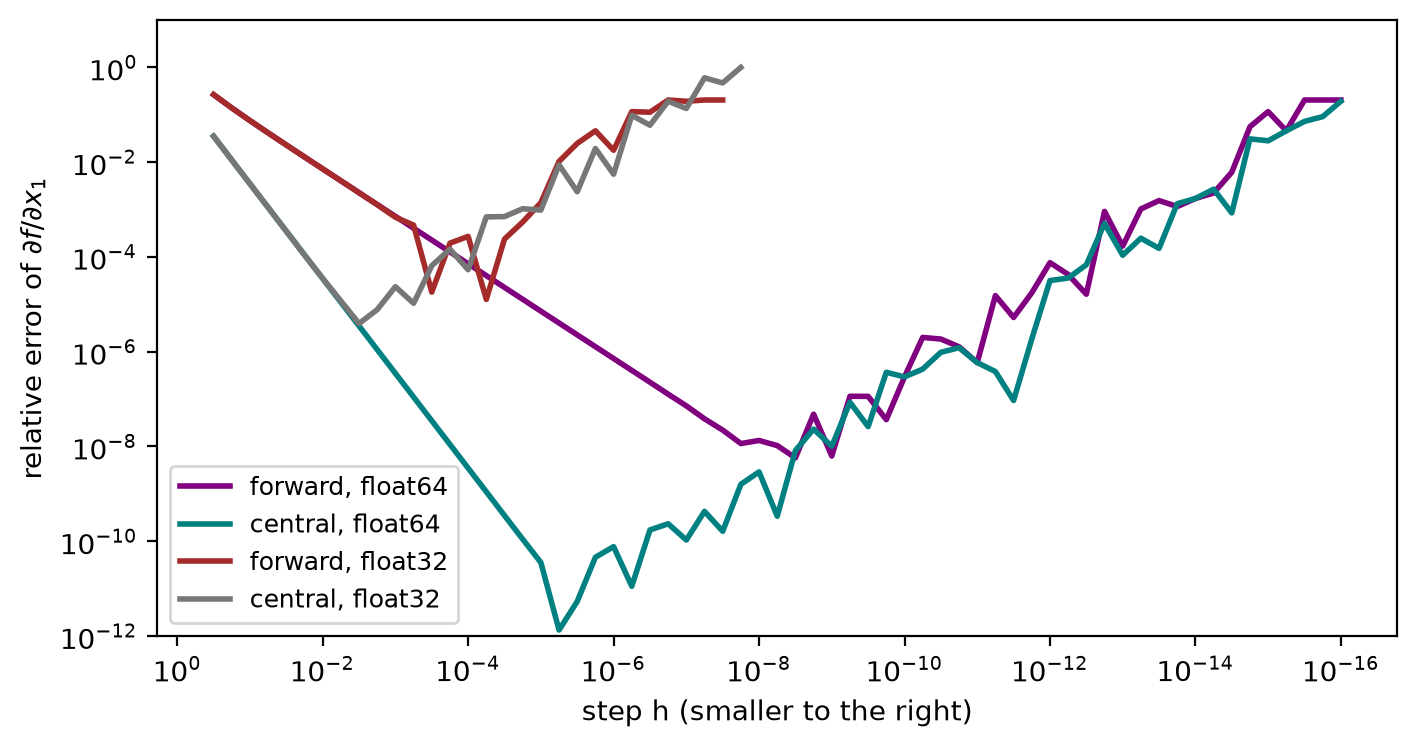

In [6]:
# @title Static version (skipped in the deck): what GitHub, nbviewer and a PDF export show
fig_fd, ax = plt.subplots(figsize=(8, 4))
for (p, s), col in {("float64", "forward"): "purple", ("float64", "central"): "teal", ("float32", "forward"): "brown", ("float32", "central"): "#777"}.items():
    e = np.array([np.nan if x is None else x for x in _fd_data["err"][p][s]])
    ax.loglog(10.0**LOG_H, np.maximum(e, 1e-12), color=col, lw=2, label=f"{s}, {p}")
ax.invert_xaxis(); ax.set_xlabel("step h (smaller to the right)"); ax.set_ylabel(r"relative error of $\partial f/\partial x_1$")
ax.set_ylim(1e-12, 10); ax.legend(fontsize=9)
plt.close(fig_fd)
fig_fd

* Double precision, forward differences: the best $h$ is about $10^{-8}$, and the derivative has only about 8 correct digits of 16.
* Central differences, $\frac{f(\mathbf{x}+h\mathbf{e}_i) - f(\mathbf{x}-h\mathbf{e}_i)}{2h}$: truncation error $\propto h^2$, so a larger best $h$ and more digits (here about 12), for $2D_x$ evaluations per gradient.
* Single precision (the default of PyTorch, and of GPUs): the best forward difference has only about 5 correct digits.

## Automatic differentiation: split $f$ into elementary operations

Another example: $f(x_1, x_2) = x_2\, e^{x_1} \sqrt{x_1 + x_2 e^{x_1}}$. Name the inputs $f_1 = x_1$ and $f_2 = x_2$, and evaluate in the usual **order of operations** (parentheses, exponents, multiplication and division, addition and subtraction):

| Step | Operation | Node |
|---|---|---|
| inside the parentheses: exponent | $e^{x_1}$ | $f_3 = e^{f_1}$ |
| inside the parentheses: multiplication | $x_2 e^{x_1}$ | $f_4 = f_2\, f_3$ |
| inside the parentheses: addition | $x_1 + x_2 e^{x_1}$ | $f_5 = f_1 + f_4$ |
| exponent | $\left(x_1 + x_2 e^{x_1}\right)^{1/2}$ | $f_6 = \sqrt{f_5}$ |
| multiplication | $x_2 e^{x_1} \cdot \sqrt{\ldots}$ | $f_7 = f_4\, f_6$ |

* $x_2 e^{x_1}$ appears twice in $f$, but it is computed once ($f_4$) and **used twice**.
* Every node is an elementary operation whose derivative we know: $\frac{\partial f_3}{\partial f_1} = e^{f_1}$, $\frac{\partial f_4}{\partial f_3} = f_2$, $\frac{\partial f_6}{\partial f_5} = \frac{1}{2\sqrt{f_5}}$, ...
* Autodiff libraries keep these rules in a **table of derivatives**: one entry per elementary operation (in PyTorch, the file `derivatives.yaml` lists hundreds of operations). Every gradient is assembled from these entries: no symbolic differentiation of the whole $f$, no finite differences, only exact local derivatives evaluated at the stored values.

### The computational graph is a DAG

A **directed acyclic graph** (DAG): all edges point in one direction, and there are no cycles. You can follow the edges from one node to another without ever ending up back where you started. An edge $f_j \to f_k$ means that $f_k$ uses $f_j$: $f_k$ is a **child** of $f_j$.

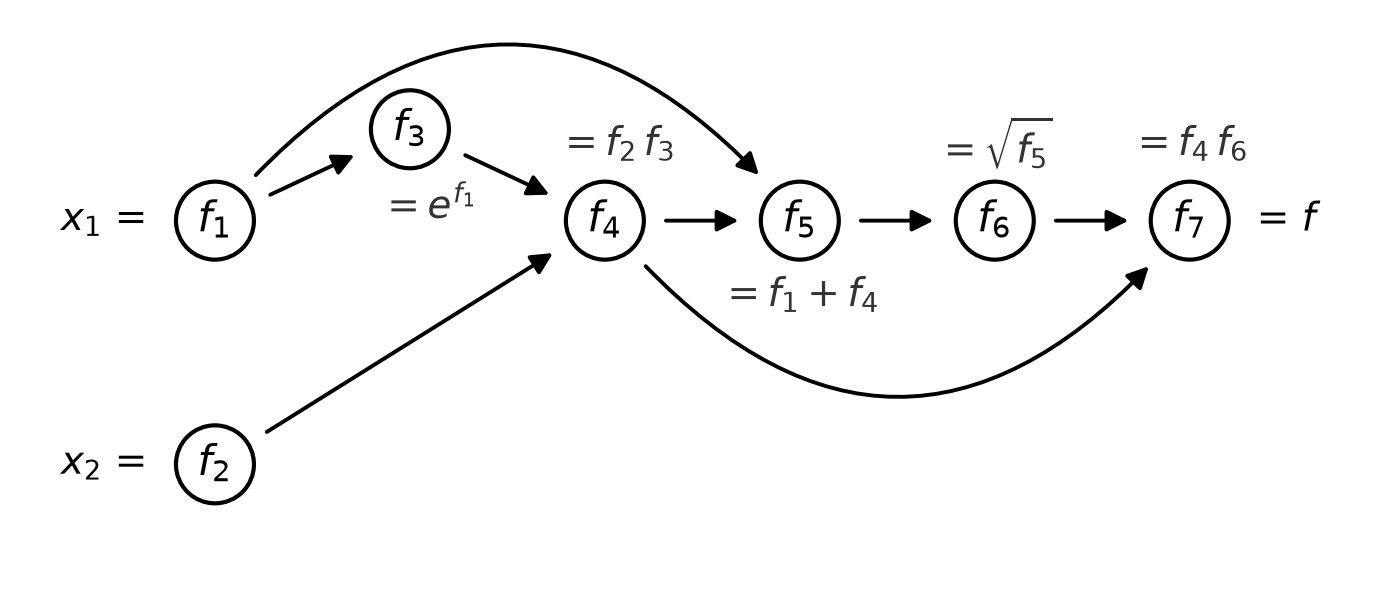

In [7]:
fig_dag_plain

* Each node applies one elementary operation to its parents (written next to it); an arrow $f_j \to f_k$ carries the value of $f_j$ into $f_k$.
* The **leaves** are what we differentiate with respect to: here $x_1$ and $x_2$; in machine learning, the weights (as in the graph of logistic regression). A coefficient in $f$ would simply be one more leaf, feeding a multiplication, whether we treat it as a constant or as a variable.

### The derivative adds up the paths

$\partial f_7/\partial f_4$: there are two paths from $f_4$ to $f_7$. Along each path, multiply the derivatives (the chain rule); then **add the paths**:

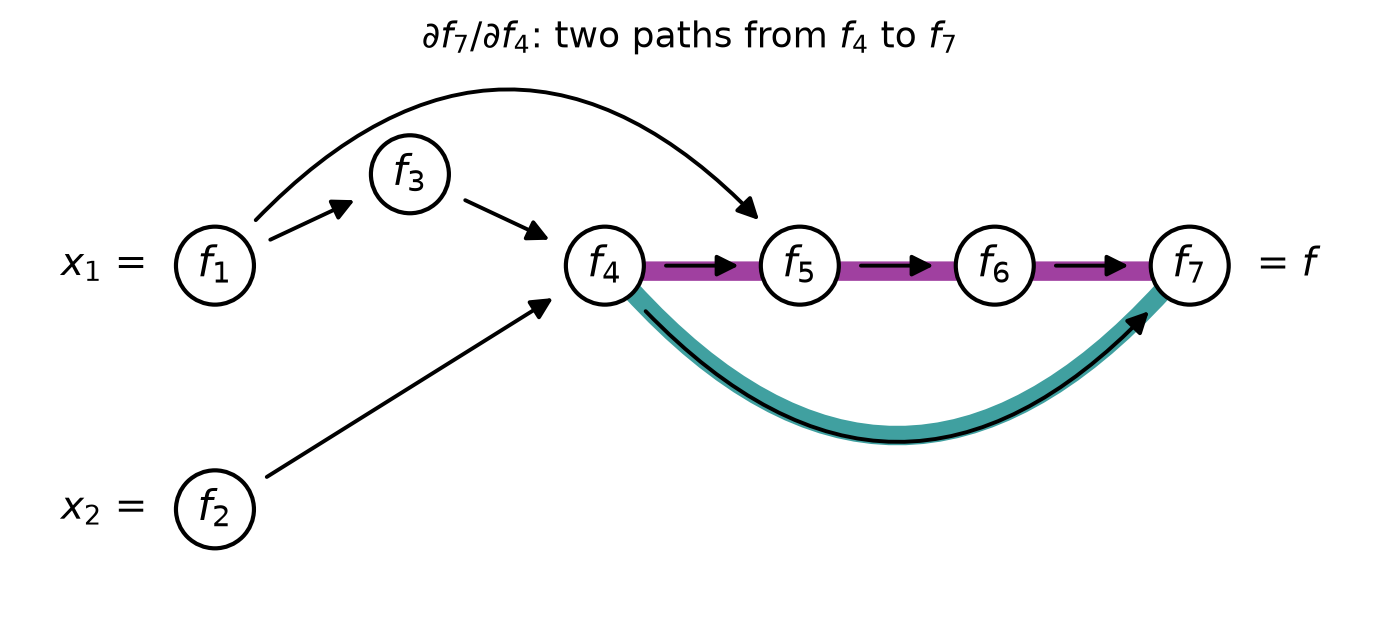

In [8]:
fig_paths_4

$$
\frac{\partial f_7}{\partial f_4} = {\color{purple}{\frac{\partial f_7}{\partial f_6}\frac{\partial f_6}{\partial f_5}\frac{\partial f_5}{\partial f_4}}} + {\color{teal}{\frac{\partial f_7}{\partial f_4}\Big|_{\text{direct}}}}
$$

$\partial f_7/\partial f_1$: three paths.

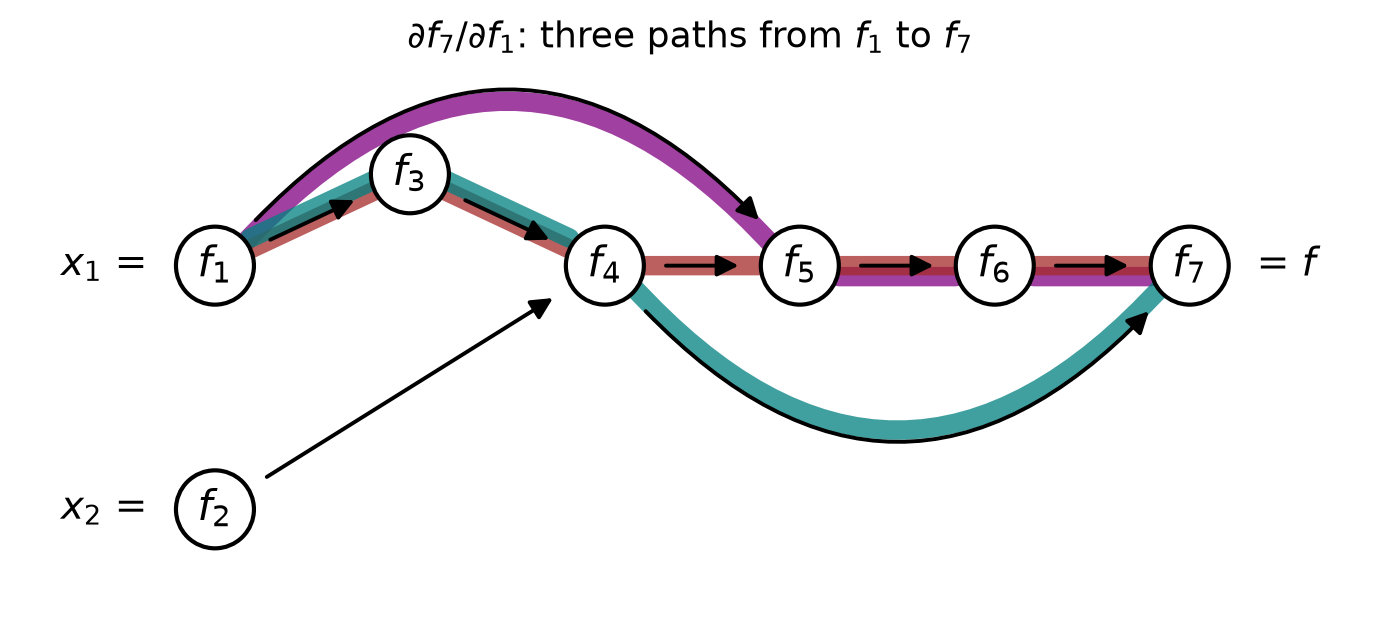

In [9]:
fig_paths_1

$$
\frac{\partial f_7}{\partial f_1} = {\color{purple}{\frac{\partial f_7}{\partial f_6}\frac{\partial f_6}{\partial f_5}\frac{\partial f_5}{\partial f_1}}} + {\color{brown}{\frac{\partial f_7}{\partial f_6}\frac{\partial f_6}{\partial f_5}\frac{\partial f_5}{\partial f_4}\frac{\partial f_4}{\partial f_3}\frac{\partial f_3}{\partial f_1}}} + {\color{teal}{\frac{\partial f_7}{\partial f_4}\frac{\partial f_4}{\partial f_3}\frac{\partial f_3}{\partial f_1}}}
$$

The paths share their ends: every time the flow splits, a new path appears, and where it repeats we reuse what we already computed. Collect the shared factors:

$$
\frac{\partial f_7}{\partial f_1} = \frac{\partial f_7}{\partial f_6}\frac{\partial f_6}{\partial f_5}\left(\frac{\partial f_5}{\partial f_1} + \frac{\partial f_5}{\partial f_4}\frac{\partial f_4}{\partial f_3}\frac{\partial f_3}{\partial f_1}\right) + \frac{\partial f_7}{\partial f_4}\frac{\partial f_4}{\partial f_3}\frac{\partial f_3}{\partial f_1}
$$

This is one rule, applied from the output backwards. Call $\bar{f}_j = \partial f_7/\partial f_j$ the **adjoint** of node $j$:

$$
\bar{f}_j = \sum_{k \,\in\, \text{children}(j)} \bar{f}_k \, \frac{\partial f_k}{\partial f_j}, \qquad \bar{f}_7 = 1
$$

In [10]:
# @title Figure code: forward and reverse mode, one step at a time (interactive)
# Hidden. Python evaluates every node, every tangent (forward mode) and every adjoint (reverse mode) at x = (0.5, 2);
# each step of the slider shows one of these computations. The renderer only draws the stored steps.
v = {1: X1, 2: X2}
v[3] = np.exp(v[1]); v[4] = v[2] * v[3]; v[5] = v[1] + v[4]; v[6] = np.sqrt(v[5]); v[7] = v[4] * v[6]
OPS = {1: "x₁", 2: "x₂", 3: "exp(f₁)", 4: "f₂ · f₃", 5: "f₁ + f₄", 6: "√f₅", 7: "f₄ · f₆"}
LOCAL = {(1, 3): ("e^f₁", v[3]), (2, 4): ("f₃", v[3]), (3, 4): ("f₂", v[2]), (1, 5): ("1", 1.0), (4, 5): ("1", 1.0),
         (5, 6): ("1/(2√f₅)", 0.5 / v[6]), (4, 7): ("f₆", v[6]), (6, 7): ("f₄", v[4])}   # the local derivative ∂f_b/∂f_a
SUB = "₀₁₂₃₄₅₆₇"
fmt = lambda x: f"{x:.4f}"

def forward_steps(seed):
    """Values and tangents (∂f_j/∂x_seed), node by node, in one forward sweep."""
    t, steps = {}, []
    for j in range(1, 8):
        parents = [a for (a, b) in LOCAL if b == j]
        if j <= 2:
            t[j] = 1.0 if j == seed else 0.0
            how = f"ḟ{SUB[j]} = {'1' if j == seed else '0'} (we differentiate with respect to x{SUB[seed]})"
        else:
            t[j] = sum(LOCAL[(a, j)][1] * t[a] for a in parents)
            terms = " + ".join(f"(∂f{SUB[j]}/∂f{SUB[a]}) ḟ{SUB[a]}" for a in parents)
            nums = " + ".join(f"{LOCAL[(a, j)][0]} · {fmt(t[a])}" for a in parents)
            how = f"ḟ{SUB[j]} = {terms} = {nums} = <b>{fmt(t[j])}</b>"
        steps.append({"node": j, "seed": seed, "edges": [[a, j] for a in parents], "known_v": list(range(1, j + 1)), "known_t": list(range(1, j + 1)),
                      "known_a": [], "t": {k: t[k] for k in t}, "a": {},
                      "text": f"f{SUB[j]} = {OPS[j]} = <b>{fmt(v[j])}</b><br>{how}"})
    steps[-1]["text"] += f"<br>One forward sweep gives the derivative with respect to <b>one</b> input: ∂f/∂x{SUB[seed]} = {fmt(t[7])}."
    return steps

def reverse_steps():
    """The forward sweep (values only), then the reverse sweep: adjoints f̄_j = ∂f₇/∂f_j = Σ over children k of f̄_k ∂f_k/∂f_j."""
    steps = []
    for j in range(1, 8):
        parents = [a for (a, b) in LOCAL if b == j]
        steps.append({"node": j, "edges": [[a, j] for a in parents], "known_v": list(range(1, j + 1)), "known_t": [], "known_a": [],
                      "t": {}, "a": {}, "text": f"Forward sweep (store every value): f{SUB[j]} = {OPS[j]} = <b>{fmt(v[j])}</b>"})
    a = {7: 1.0}
    steps.append({"node": 7, "edges": [], "known_v": list(range(1, 8)), "known_t": [], "known_a": [7], "t": {}, "a": dict(a),
                  "text": "Reverse sweep. Start at the output: f̄₇ = ∂f₇/∂f₇ = <b>1</b>"})
    for j in [6, 5, 4, 2, 3, 1]:                  # the order of PyTorch's backward() (checked with hooks): a node waits for all its children
        children = [b for (p, b) in LOCAL if p == j]
        a[j] = sum(a[k] * LOCAL[(j, k)][1] for k in children)
        terms = " + ".join(f"f̄{SUB[k]} (∂f{SUB[k]}/∂f{SUB[j]})" for k in children)
        nums = " + ".join(f"{fmt(a[k])} · {LOCAL[(j, k)][0]}" for k in children)
        note = (f"<br><i>f{SUB[j]} has {len(children)} children: it waits until all of them have passed back their share, then sums (the paths that meet here).</i>"
                if len(children) > 1 else "")
        if j == 2:
            note = "<br><i>f₄ has passed back to both its parents, f₂ and f₃. PyTorch finishes the input f₂ first; f₁ must still wait for f₃.</i>"
        steps.append({"node": j, "edges": [[j, k] for k in children], "known_v": list(range(1, 8)), "known_t": [],
                      "known_a": sorted(a), "t": {}, "a": dict(a), "text": f"f̄{SUB[j]} = {terms} = {nums} = <b>{fmt(a[j])}</b>{note}"})
    steps[-1]["text"] += f"<br>One reverse sweep gives the derivatives with respect to <b>all</b> inputs: ∂f/∂x₁ = {fmt(a[1])}, ∂f/∂x₂ = {fmt(a[2])}."
    return steps

_modes = {"forward mode, ∂/∂x₁": forward_steps(1), "forward mode, ∂/∂x₂": forward_steps(2), "reverse mode": reverse_steps()}
assert abs(_modes["forward mode, ∂/∂x₁"][-1]["t"][7] - DF_EXACT[0]) < 1e-12 and abs(_modes["reverse mode"][-1]["a"][1] - DF_EXACT[0]) < 1e-12
assert abs(_modes["forward mode, ∂/∂x₂"][-1]["t"][7] - DF_EXACT[1]) < 1e-12 and abs(_modes["reverse mode"][-1]["a"][2] - DF_EXACT[1]) < 1e-12
_step_data = {"pos": {k: list(p) for k, p in DAG_POS.items()}, "edges": DAG_EDGES, "curved": {f"{a}-{b}": r for (a, b), r in DAG_CURVED.items()},
              "v": {k: v[k] for k in v}, "ops": OPS, "modes": _modes}
_step_html = r"""<div style="font-family:system-ui,sans-serif;max-width:940px">
<canvas id="ad-c" width="1840" height="640" style="width:920px;height:320px;border:1px solid #ccc"></canvas>
<div style="display:flex;gap:20px;margin-top:8px;font-size:13px;align-items:center;flex-wrap:wrap">
  <label>mode: <select id="ad-m"></select></label>
  <label>step: <input id="ad-s" type="range" min="0" value="0" style="width:320px;vertical-align:middle"> <b id="ad-sl"></b></label>
  <button id="ad-p">◀</button><button id="ad-n">▶</button>
</div>
<div id="ad-t" style="font-size:16px;margin-top:8px;line-height:1.7;min-height:80px"></div>
</div>
<script>
(function(){
 var M=__DATA__, S=2, c=document.getElementById('ad-c'), g=c.getContext('2d');
 var sel=document.getElementById('ad-m'), sl=document.getElementById('ad-s');
 Object.keys(M.modes).forEach(function(m){var o=document.createElement('option');o.textContent=m;sel.appendChild(o);});
 var X0=-1.4, X1=9.0, Y0=-3.2, Y1=2.0, R=26*S, SUB='₀₁₂₃₄₅₆₇';
 function px(x){return (x-X0)/(X1-X0)*c.width;} function py(y){return (Y1-y)/(Y1-Y0)*c.height;}
 function ctrl(a,b){var A=M.pos[a],B=M.pos[b],r=M.curved[a+'-'+b]||0,mx=(A[0]+B[0])/2,my=(A[1]+B[1])/2,dx=B[0]-A[0],dy=B[1]-A[1];
   return [mx+r*dy, my-r*dx];}   // the control point of the arc (as matplotlib's arc3)
 function edge(a,b,col,lw,arrow){var A=M.pos[a],B=M.pos[b],C=ctrl(a,b);
   var ax=px(A[0]),ay=py(A[1]),bx=px(B[0]),by=py(B[1]),cx=px(C[0]),cy=py(C[1]);
   var t0=R/Math.hypot(cx-ax,cy-ay), t1=R/Math.hypot(bx-cx,by-cy);
   var sx=ax+(cx-ax)*t0, sy=ay+(cy-ay)*t0, ex=bx-(bx-cx)*t1, ey=by-(by-cy)*t1;
   g.save();g.strokeStyle=col;g.lineWidth=lw*S;g.beginPath();g.moveTo(sx,sy);g.quadraticCurveTo(cx,cy,ex,ey);g.stroke();
   if(arrow){var an=Math.atan2(ey-cy,ex-cx),L=11*S;g.fillStyle=col;g.beginPath();g.moveTo(ex,ey);
     g.lineTo(ex-L*Math.cos(an-0.35),ey-L*Math.sin(an-0.35));g.lineTo(ex-L*Math.cos(an+0.35),ey-L*Math.sin(an+0.35));g.fill();}
   g.restore();}
 function draw(){
  var steps=M.modes[sel.value], k=+sl.value, st=steps[k], rev=sel.value==='reverse mode';
  g.clearRect(0,0,c.width,c.height);
  var hot={}; st.edges.forEach(function(e){hot[e[0]+'-'+e[1]]=1;});
  M.edges.forEach(function(e){var h=hot[e[0]+'-'+e[1]];
    if(h) edge(e[0],e[1],rev&&k>=7?'brown':'teal',5,false);
    edge(e[0],e[1],'#000',1.4,true);});
  Object.keys(M.pos).forEach(function(n){var p=M.pos[n],x=px(p[0]),y=py(p[1]),cur=(+n===st.node);
    g.save();g.beginPath();g.arc(x,y,R,0,7);g.fillStyle=cur?(rev&&k>=7?'#f1e3dc':'#d9efef'):'#fff';g.fill();
    g.lineWidth=(cur?3:1.5)*S;g.strokeStyle='#000';g.stroke();
    g.fillStyle='#000';g.font='italic '+(17*S)+'px serif';g.textAlign='center';g.fillText('f'+SUB[n],x,y+6*S);
    g.font=(12*S)+'px system-ui';
    if(st.known_v.indexOf(+n)>=0){g.fillStyle='#333';g.fillText(M.v[n].toFixed(3),x,y+R+15*S);}
    if(st.known_t.indexOf(+n)>=0){g.fillStyle='purple';g.fillText('∂f'+SUB[n]+'/∂x'+SUB[st.seed]+' = '+st.t[n].toFixed(3),x,y+R+31*S);}
    if(st.known_a.indexOf(+n)>=0){g.fillStyle='brown';g.fillText('∂f₇/∂f'+SUB[n]+' = '+st.a[n].toFixed(3),x,+n===3?y+R+31*S:y-R-9*S);}   // f3: below (the arc passes above it)
    g.restore();});
  g.save();g.font=(13*S)+'px system-ui';g.fillStyle='#333';g.textAlign='right';
  g.fillText('x₁ =',px(M.pos[1][0])-R-6*S,py(M.pos[1][1])+5*S);g.fillText('x₂ =',px(M.pos[2][0])-R-6*S,py(M.pos[2][1])+5*S);
  g.textAlign='left';g.fillText('= f',px(M.pos[7][0])+R+6*S,py(M.pos[7][1])+5*S);
  g.fillStyle='#555';g.font=(12*S)+'px system-ui';g.textAlign='left';var LX=px(2.6),LY=py(-2.15);g.fillText('below each node: its value (black), and in forward mode its',LX,LY);g.fillText('derivative with respect to the input (purple); above it, in reverse',LX,LY+15*S);g.fillText('mode: its adjoint, the derivative of the output (brown)',LX,LY+30*S);g.restore();
  document.getElementById('ad-sl').textContent=(k+1)+' / '+steps.length;
  document.getElementById('ad-t').innerHTML=st.text;
 }
 function reset(){sl.max=M.modes[sel.value].length-1;sl.value=0;draw();}
 sel.addEventListener('change',reset); sl.addEventListener('input',draw);
 document.getElementById('ad-p').addEventListener('click',function(){sl.value=Math.max(0,+sl.value-1);draw();});
 document.getElementById('ad-n').addEventListener('click',function(){sl.value=Math.min(+sl.max,+sl.value+1);draw();});
 sel.value='reverse mode'; reset();
})();
</script>
""".replace("__DATA__", json.dumps(_step_data))

### Forward mode and reverse mode, one step at a time

* **Forward mode**: carry the derivative with respect to **one input** along with the values, from the inputs to the output ($\dot{f}_j = \partial f_j/\partial x_i$).
* **Reverse mode**: first a forward sweep that stores every value, then the adjoints from the output back to the inputs.

In [11]:
HTML(_step_html)

In [12]:
# @title Static version (skipped in the deck): the reverse sweep, written out
print(f"x = ({X1}, {X2})")
for s in _modes["reverse mode"]:
    print(re.sub("<[^>]+>", "", s["text"].replace("<br>", "\n    ")))
print(f"symbolic check: df/dx1 = {DF_EXACT[0]:.10f}, df/dx2 = {DF_EXACT[1]:.10f}")

x = (0.5, 2.0)
Forward sweep (store every value): f₁ = x₁ = 0.5000
Forward sweep (store every value): f₂ = x₂ = 2.0000
Forward sweep (store every value): f₃ = exp(f₁) = 1.6487
Forward sweep (store every value): f₄ = f₂ · f₃ = 3.2974
Forward sweep (store every value): f₅ = f₁ + f₄ = 3.7974
Forward sweep (store every value): f₆ = √f₅ = 1.9487
Forward sweep (store every value): f₇ = f₄ · f₆ = 6.4257
Reverse sweep. Start at the output: f̄₇ = ∂f₇/∂f₇ = 1
f̄₆ = f̄₇ (∂f₇/∂f₆) = 1.0000 · f₄ = 3.2974
f̄₅ = f̄₆ (∂f₆/∂f₅) = 3.2974 · 1/(2√f₅) = 0.8461
f̄₄ = f̄₅ (∂f₅/∂f₄) + f̄₇ (∂f₇/∂f₄) = 0.8461 · 1 + 1.0000 · f₆ = 2.7948
    f₄ has 2 children: it waits until all of them have passed back their share, then sums (the paths that meet here).
f̄₂ = f̄₄ (∂f₄/∂f₂) = 2.7948 · f₃ = 4.6078
    f₄ has passed back to both its parents, f₂ and f₃. PyTorch finishes the input f₂ first; f₁ must still wait for f₃.
f̄₃ = f̄₄ (∂f₄/∂f₃) = 2.7948 · f₂ = 5.5895
f̄₁ = f̄₃ (∂f₃/∂f₁) + f̄₅ (∂f₅/∂f₁) = 5.5895 · e^f₁ + 0.846

* Forward mode: **one sweep per input**. Reverse mode: **one sweep per output**, for the derivatives with respect to all the inputs.
* A loss has one output and millions of inputs (the weights): reverse mode. Its cost is a small multiple of one evaluation of $f$ (one local derivative per edge), whatever the number of inputs, where finite differences need $D_x + 1$ evaluations. The price is memory: the forward sweep stores every value.

#### Note: vectors, Jacobians, and what autodifferentiation packages (like PyTorch) do

In a network, each node is a layer: a vector-valued function $\mathbf{n}_{l+1} = \mathbf{f}_{l+1}(\mathbf{n}_l)$, whose local derivative is a **Jacobian** matrix $\mathbf{J}_{l+1} = \partial\mathbf{n}_{l+1}/\partial\mathbf{n}_l$. The chain rule multiplies Jacobians, $\mathbf{J}_{L+1}\cdots\mathbf{J}_1$, and the order of the products is the whole difference between the two modes:

* **Reverse mode** starts from the scalar loss: the adjoint is a row vector, and each step is a **vector-Jacobian product** (VJP), $\bar{\mathbf{n}}_l^T = \bar{\mathbf{n}}_{l+1}^T\mathbf{J}_{l+1}$. The Jacobian itself is never formed: for a linear layer $\mathbf{n}_{l+1} = \mathbf{W}\mathbf{n}_l + \mathbf{b}$, the VJP is simply $\bar{\mathbf{n}}_{l+1}^T\mathbf{W}$.
* **Forward mode** starts from one input direction $\mathbf{v}$: each step is a **Jacobian-vector product** (JVP), $\dot{\mathbf{n}}_{l+1} = \mathbf{J}_{l+1}\dot{\mathbf{n}}_l$.

PyTorch's `backward()` runs VJPs; `torch.func.jvp` and `torch.func.vjp` expose both. Forward mode wins when there are fewer inputs than outputs (e.g. the sensitivity of a whole field to one design parameter).

#### Note: in which order, in practice?

**The forward sweep follows the program, not the formula.** The order of operations (PEMDAS) fixes the *structure* of the graph: which operation applies to which operands. The *time* order is the order in which the program runs: Python evaluates the left operand before the right one, and the arguments of a function before the function. Two consequences:
* Autodiff differentiates the **program**. Written literally, `x2*torch.exp(x1)*torch.sqrt(x1 + x2*torch.exp(x1))` records 7 operations: $e^{x_1}$ and $x_2e^{x_1}$ are computed twice, and there is no shared node $f_4$. Our graph, with 5 operations, is the graph of `t = x2*torch.exp(x1); f = t*torch.sqrt(x1 + t)`.
* Where the graph branches, any order that respects the arrows (a *topological order*) gives the same result; a GPU may even run independent branches in parallel. The interactive plot follows Python's order: $f_3, f_4, f_5, f_6, f_7$.

**Forward mode** (`torch.func.jvp`, or `jax.jvp`) carries each value and its derivative together, operation by operation, in this same order: one step of the interactive plot per operation.

**Reverse mode** (`backward()`). During the forward sweep PyTorch records every operation and stores its inputs (the "tape"). `backward()` starts from the last operation, and processes a node only when **all its children** have passed back their contribution: it counts them. That is why $f_4$, which feeds both $f_5$ and $f_7$, waits for $f_5$; and why $f_1$ comes last. Hooks on our example give the order $f_7, f_6, f_5, f_4, f_2, f_3, f_1$, the order of the interactive plot. (In PyTorch each node *pushes* its share $\bar{f}_k\,\partial f_k/\partial f_j$ to its parents, where the shares are summed; the plot shows the same sum when it is complete.)

### What about a loop?

$$
\texttt{for } i = 1, 2, 3: \quad y = y + \frac{\sqrt{x}\; e^{ix}}{x^3}
$$

**Unroll** the loop: the code that runs is

$$
y = \frac{\sqrt{x}\,e^{x}}{x^3} + \frac{\sqrt{x}\,e^{2x}}{x^3} + \frac{\sqrt{x}\,e^{3x}}{x^3}
$$

a DAG like any other. Automatic differentiation records the operations **as the code runs** (a "tape"), so loops, `if`s and function calls are fine: it differentiates the graph of the run that actually happened. (And $\sqrt{x}$ and $x^3$ are computed once, and reused three times.)

### Note: Implementing reverse mode automatic differentiation in 20 lines of code

Each value remembers its parents and the local derivative with respect to each of them; `backward` visits the nodes from the output back, and adds $\bar{f}_k\,\partial f_k/\partial f_j$ into each parent: the sum over children.

In [13]:
class Node:
    def __init__(self, value, parents=()):
        self.value, self.parents, self.adjoint = value, parents, 0.0   # parents: (node, local derivative) pairs
    def __add__(self, other):
        return Node(self.value + other.value, ((self, 1.0), (other, 1.0)))
    def __mul__(self, other):
        return Node(self.value * other.value, ((self, other.value), (other, self.value)))

def exp(a):
    return Node(np.exp(a.value), ((a, np.exp(a.value)),))

def sqrt(a):
    return Node(np.sqrt(a.value), ((a, 0.5 / np.sqrt(a.value)),))

def backward(output):
    order, seen = [], set()
    def visit(node):                       # every node after all the nodes it uses (a topological order)
        if id(node) not in seen:
            seen.add(id(node))
            for parent, _ in node.parents:
                visit(parent)
            order.append(node)
    visit(output)
    output.adjoint = 1.0                   # the adjoint of the output with respect to itself
    for node in reversed(order):           # from the output back to the inputs
        for parent, local in node.parents:
            parent.adjoint += node.adjoint * local     # the sum over the children of the parent

As we will see in the next lectures where we cover artificial neural networks, there are several efficient and open-source (!) **automatic differentiation** libraries available online. The most popular at the moment are `JAX` and `PyTorch`.

You can check by yourself that our simple 20 line code does automatic differentiation as well as `PyTorch`, and we can even compare the derivative calculation with **symbolic differentiation** (which gives the exact expression of the derivative) by using `scipy`.

In [14]:
f1, f2 = Node(0.5), Node(2.0)              # x1, x2
f3 = exp(f1); f4 = f2 * f3; f5 = f1 + f4; f6 = sqrt(f5); f7 = f4 * f6
backward(f7)

x = torch.tensor([0.5, 2.0], requires_grad=True)       # the same, with PyTorch
f = x[1] * torch.exp(x[0]) * torch.sqrt(x[0] + x[1] * torch.exp(x[0]))
f.backward()
print("ours:    df/dx1 =", f1.adjoint, "  df/dx2 =", f2.adjoint)
print("PyTorch: df/dx1 =", x.grad[0].item(), "  df/dx2 =", x.grad[1].item())
print("sympy:   df/dx1 =", DF_EXACT[0], "  df/dx2 =", DF_EXACT[1])

ours:    df/dx1 = 10.061633652129641   df/dx2 = 4.607786366003566
PyTorch: df/dx1 = 10.06163365212964   df/dx2 = 4.607786366003566
sympy:   df/dx1 = 10.06163365212964   df/dx2 = 4.607786366003565


## Note about backpropagation

Furthermore, as we will also discuss in artificial neural networks, reverse mode automatic differentiation is referred to **backpropagation** in the machine learning literature. In other words:

* **Backpropagation is reverse-mode automatic differentiation applied to the loss** of a neural network: a forward pass through the layers stores the activations, and a backward pass gives $\partial\mathcal{L}/\partial$ every weight and bias, at the cost of about one more pass. (Rumelhart, Hinton & Williams, 1986, made it the way to train neural networks.)

We can also check the gradient calculations that we determined in Lecture 24 for logistic regression, $\boldsymbol{\Phi}^T(\boldsymbol{\rho}-\mathbf{y})$, and compare it with PyTorch's gradient from automatic differentiation (backpropagation):

In [15]:
rng = np.random.default_rng(0)
x_data = torch.tensor(rng.uniform(-2, 2, 5))                    # 5 made-up points
y_data = torch.tensor(rng.integers(0, 2, 5), dtype=torch.float64)  # their classes, 0 or 1
Phi = torch.stack([torch.ones(5), x_data], dim=1)               # basis functions [1, x], an N x M matrix
w = torch.tensor([0.7, -0.3], requires_grad=True)

rho = torch.sigmoid(Phi @ w)
nll = -torch.sum(y_data * torch.log(rho) + (1 - y_data) * torch.log(1 - rho))
nll.backward()                                                  # reverse mode: the whole gradient in one sweep

by_hand = Phi.T @ (rho.detach() - y_data)                       # the formula of Lecture 24
for d in range(2):
    print(f"dNLL/dw{d}: PyTorch {w.grad[d].item():+.12f}   by hand {by_hand[d].item():+.12f}")

dNLL/dw0: PyTorch -1.502597138818   by hand -1.502597138818
dNLL/dw1: PyTorch +0.353115752106   by hand +0.353115752106


## Which optimizer, when?

We now have three families of optimizers:
* Zeroth-order: we only use values of $f$. Examples: random search, Nelder-Mead, CMA-ES (Lecture 26)
* First-order: we need to evaluate $f$ and its gradient. Examples: gradient descent, Adam, L-BFGS (Lecture 27)
    - Note: gradient calculation in reverse mode automatic differentiation makes the gradient cost about one more evaluation of $f$, **whatever dimension $D$** (Lecture 28)
* Second-order: we need to evaluate $f$, its gradient and its Hessian. Example: Newton (Lecture 27)

A small benchmark, judged as in Lecture 26 (a fixed budget, many repetitions), on four kinds of problems:
* smooth and convex: the logistic regression loss of Lecture 24, with $D$ from 2 to 2000 weights
* many local minima: the Rastrigin function
* noisy evaluations: the smooth problem with $D = 20$, where $f$ and its gradient come back with a different error every time (like a simulation with a tolerance), and a black box that returns noisy values

**Cost** = evaluations of $f$: a gradient costs one more, a Hessian $D$ more.

In [16]:
# @title Figure code: which optimizer, when? A small benchmark (data for the interactive plot)
# Hidden. Six optimizers on four kinds of problems, 20 repetitions each (10 at D = 2000), every one restarted from a new
# random point when it stops, until the budget is spent. Cost unit: one evaluation of f (on the full data). A gradient
# costs one more unit (reverse mode: about as much as f for these functions), a Hessian costs D units (D Hessian-vector
# products); Newton's linear solve is not charged (in its favor). After every call we record the TRUE f - f* of the point
# the optimizer would return: the best point seen (deterministic problems), or its current iterate, mean or best noisy
# value (noisy problems). Running everything takes about 15 minutes on 16 cores (the D = 2000 problem dominates), so the
# results are saved in optimizer_benchmark.json and loaded from there when the file exists.
import os, warnings
from pathlib import Path
from scipy.optimize import minimize

class _Spent(Exception):
    pass

class Oracle:
    def __init__(self, prob, budget, noisy):
        self.p, self.budget, self.noisy, self.cost, self.trace = prob, budget, noisy, 0.0, []
        self.best_obs, self.rec, self.next_ck = np.inf, None, 1e-3
    def _charge(self, c, x, fobs):
        if self.cost + c > self.budget:
            raise _Spent
        self.cost += c
        if not self.noisy and fobs < self.best_obs:
            self.best_obs, self.rec = fobs, x.copy()
        if self.rec is None:
            self.rec = x.copy()
        if self.cost >= self.next_ck:                                     # 40 checkpoints per decade of cost
            self.trace.append((self.cost, self.p.true(self.rec)))
            while self.next_ck <= self.cost:
                self.next_ck *= 10**(1/40)
    def f(self, x):
        v = self.p.f(x); self._charge(self.p.c_f, x, v); return v
    def fg(self, x):
        v, g = self.p.fg(x); self._charge(self.p.c_f + self.p.c_g, x, v); return v, g
    def fgh(self, x):
        v, g, H = self.p.fgh(x); self._charge(self.p.c_f + self.p.c_g + self.p.c_h, x, v); return v, g, H

class Logistic:
    """Mean NLL of logistic regression + (lam/2)|w|^2 on N points with correlated features; optional minibatches."""
    def __init__(self, D, N=1000, batch=None, lam=1e-2):
        r = np.random.default_rng(1000 + D)
        Q, _ = np.linalg.qr(r.standard_normal((D, D)))
        sc = np.logspace(0, -1, D) if D > 1 else np.ones(1)
        self.X = (r.standard_normal((N, D))*sc) @ Q.T
        w_true = r.standard_normal(D)*2/np.sqrt(np.mean(sc**2)*D)
        self.y = (r.uniform(size=N) < 1/(1 + np.exp(-self.X @ w_true))).astype(float)
        self.N, self.D, self.lam, self.batch, self.lo, self.hi = N, D, lam, batch, -5.0, 5.0
        self.c_f = self.c_g = (batch or N)/N
        self.c_h = D*(batch or N)/N
        self.rng = np.random.default_rng(0)
        w = np.zeros(D)
        for _ in range(50):                                               # the exact minimum, by Newton
            _, g, H = self._fgh(w, np.arange(N)); w -= np.linalg.solve(H, g)
        self.fstar = self._fgh(w, np.arange(N))[0]
    def _fgh(self, w, idx, need=3):
        X, y = self.X[idx], self.y[idx]; a = X @ w
        f = np.mean(np.logaddexp(0, a) - y*a) + 0.5*self.lam*w @ w
        if need == 1: return f
        p = 1/(1 + np.exp(-a)); g = X.T @ (p - y)/len(idx) + self.lam*w
        if need == 2: return f, g
        return f, g, (X.T*(p*(1 - p))) @ X/len(idx) + self.lam*np.eye(self.D)
    def _idx(self):
        return np.arange(self.N) if self.batch is None else self.rng.integers(0, self.N, self.batch)
    def f(self, w): return self._fgh(w, self._idx(), 1)
    def fg(self, w): return self._fgh(w, self._idx(), 2)
    def fgh(self, w): return self._fgh(w, self._idx(), 3)
    def true(self, w): return self._fgh(w, np.arange(self.N), 1) - self.fstar

class Rastrigin:
    """Many local minima on a bowl: 10 D + sum(x^2 - 10 cos(2 pi x)), global minimum 0 at the origin."""
    def __init__(self, D):
        self.D, self.lo, self.hi, self.c_f, self.c_g, self.c_h = D, -5.12, 5.12, 1.0, 1.0, float(D)
    def f(self, x): return 10*self.D + np.sum(x**2 - 10*np.cos(2*np.pi*x))
    def fg(self, x): return self.f(x), 2*x + 20*np.pi*np.sin(2*np.pi*x)
    def fgh(self, x): return (*self.fg(x), np.diag(2 + 40*np.pi**2*np.cos(2*np.pi*x)))
    def true(self, x): return self.f(x)

class NoisyBox:
    """A smooth function (the logistic NLL with D = 2) observed with additive noise, like a simulation or an experiment."""
    def __init__(self, seed, sigma=1e-3):
        self.L, self.D, self.lo, self.hi = Logistic(2), 2, -5.0, 5.0
        self.c_f, self.sigma, self.rng = 1.0, sigma, np.random.default_rng(seed)
    def f(self, x): return self.L.true(x) + self.sigma*self.rng.standard_normal()
    def true(self, x): return self.L.true(x)

class NoisyGrad:
    """The smooth problem (D = 20), where every value of f, every component of the gradient and of the Hessian comes back
    with Gaussian noise: like a simulation with a tolerance, or a gradient estimated from part of the data."""
    def __init__(self, seed, D=20, sigma=1e-2):
        self.L, self.D, self.lo, self.hi, self.sigma = Logistic(D), D, -5.0, 5.0, sigma
        self.c_f = self.c_g = 1.0; self.c_h = float(D); self.rng = np.random.default_rng(seed)
    def f(self, x): return self.L.true(x) + self.sigma*self.rng.standard_normal()
    def fg(self, x):
        return self.f(x), self.L._fgh(x, np.arange(self.L.N), 2)[1] + self.sigma*self.rng.standard_normal(self.D)
    def fgh(self, x):
        v, g = self.fg(x); E = self.sigma*self.rng.standard_normal((self.D, self.D))
        return v, g, self.L._fgh(x, np.arange(self.L.N), 3)[2] + (E + E.T)/2
    def true(self, x): return self.L.true(x)

def _start(p, r): return r.uniform(p.lo, p.hi, p.D)

def random_search(o, p, r):
    best = np.inf
    while True:
        x = _start(p, r); v = o.f(x)
        if o.noisy and v < best: best, o.rec = v, x.copy()

def nelder_mead(o, p, r):
    while True:
        cb = (lambda xk: setattr(o, "rec", xk.copy())) if o.noisy else None
        minimize(o.f, _start(p, r), method="Nelder-Mead", callback=cb,
                 options=dict(maxfev=10**9, xatol=1e-8, fatol=1e-12, adaptive=p.D > 5))

def lbfgs(o, p, r, fd=False):
    x0 = _start(p, r)
    while True:
        cb = (lambda xk: setattr(o, "rec", xk.copy())) if o.noisy else None
        if fd: res = minimize(o.f, x0, method="L-BFGS-B", callback=cb, options=dict(maxfun=10**9, maxiter=10**9))
        else:  res = minimize(o.fg, x0, jac=True, method="L-BFGS-B", callback=cb, options=dict(maxfun=10**9, maxiter=10**9))
        o.msgs = getattr(o, "msgs", []) + [str(res.message)]
        x0 = res.x if o.noisy else _start(p, r)        # noisy: carry on from where it stopped; otherwise restart

def newton(o, p, r):
    x = _start(p, r)
    while True:
        if o.noisy: o.rec = x.copy()
        while True:
            f, g, H = o.fgh(x)
            try:
                d = -np.linalg.solve(H, g)
            except np.linalg.LinAlgError:
                break
            if g @ d >= 0 or np.linalg.norm(g) < 1e-12:   # H not positive definite (not a descent direction), or done
                break
            a = 1.0
            while o.f(x + a*d) > f + 1e-4*a*(g @ d) and a > 1e-9:   # backtracking line search
                a /= 2
            x = x + a*d
            if o.noisy: o.rec = x.copy()
        if not o.noisy:
            x = _start(p, r)                          # restart elsewhere; noisy: carry on from where it stopped (as L-BFGS)

def adam(o, p, r, lr):
    while True:
        x = _start(p, r); m = v = 0*x; best, stall = np.inf, 0
        if o.noisy: o.rec = x.copy()
        for t in range(1, 10**9):
            f, g = o.fg(x)
            m = 0.9*m + 0.1*g; v = 0.999*v + 0.001*g*g
            x = x - lr*(m/(1 - 0.9**t))/(np.sqrt(v/(1 - 0.999**t)) + 1e-8)
            if o.noisy: o.rec = x.copy()
            elif f < best - 1e-10*max(1, abs(best)): best, stall = f, 0
            else:
                stall += 1
                if stall > 100: break                        # stalled: restart elsewhere

def cma_es(o, p, r):
    """CMA-ES (Lecture 26) with IPOP restarts: every restart doubles the population."""
    n, sigma0 = p.D, (p.hi - p.lo)/4
    lam = 4 + int(3*np.log(n))
    while True:
        mu = lam//2
        w = np.log(mu + 0.5) - np.log(np.arange(1, mu + 1)); w /= w.sum(); mueff = 1/np.sum(w**2)
        cc = (4 + mueff/n)/(n + 4 + 2*mueff/n); cs = (mueff + 2)/(n + mueff + 5)
        c1 = 2/((n + 1.3)**2 + mueff); cmu = min(1 - c1, 2*(mueff - 2 + 1/mueff)/((n + 2)**2 + mueff))
        damps = 1 + 2*max(0, np.sqrt((mueff - 1)/(n + 1)) - 1) + cs; chiN = np.sqrt(n)*(1 - 1/(4*n) + 1/(21*n**2))
        m, s, C = _start(p, r), sigma0, np.eye(n); pc, ps, it, D, B = np.zeros(n), np.zeros(n), 0, np.ones(n), np.eye(n)
        if o.noisy: o.rec = m.copy()
        while s*D.max() >= 1e-6 and s < 1e6:
            it += 1
            if (it - 1) % max(1, n//10) == 0:                  # eigendecomposition every n/10 generations
                D2, B = np.linalg.eigh(C); D = np.sqrt(np.maximum(D2, 1e-20))
            y = r.standard_normal((lam, n)) @ (B*D).T
            x = np.clip(m + s*y, p.lo, p.hi); y = (x - m)/s
            order = np.argsort([o.f(xi) for xi in x])
            yw = w @ y[order[:mu]]; m = m + s*yw
            if o.noisy: o.rec = m.copy()
            ps = (1 - cs)*ps + np.sqrt(cs*(2 - cs)*mueff)*(B @ ((B.T @ yw)/D))
            hs = np.linalg.norm(ps)/np.sqrt(1 - (1 - cs)**(2*it)) < (1.4 + 2/(n + 1))*chiN
            pc = (1 - cc)*pc + hs*np.sqrt(cc*(2 - cc)*mueff)*yw
            C = ((1 - c1 - cmu)*C + c1*(np.outer(pc, pc) + (1 - hs)*cc*(2 - cc)*C) + cmu*(y[order[:mu]].T*w) @ y[order[:mu]])
            C = (C + C.T)/2
            s *= np.exp((cs/damps)*(np.linalg.norm(ps)/chiN - 1))
        lam *= 2

OPTIMIZERS = {"random search": random_search, "Nelder-Mead": nelder_mead, "CMA-ES": cma_es, "Adam": adam,
              "L-BFGS": lbfgs, "Newton": newton, "L-BFGS + finite differences": lambda o, p, r: lbfgs(o, p, r, fd=True)}
_ALL6 = ["random search", "Nelder-Mead", "CMA-ES", "Adam", "L-BFGS", "Newton"]
SCENARIOS = {
    **{f"smooth_{D}": dict(title=f"Smooth and convex, D = {D}", make=lambda s, D=D: Logistic(D), budget=1e4,
                           noisy=False, opts=_ALL6, seeds=10 if D == 2000 else 20) for D in [2, 20, 200, 2000]},
    "multimodal_2": dict(title="Many local minima, D = 2", make=lambda s: Rastrigin(2), budget=2e3, noisy=False, opts=_ALL6, seeds=20),
    "multimodal_10": dict(title="Many local minima, D = 10", make=lambda s: Rastrigin(10), budget=1e5, noisy=False, opts=_ALL6, seeds=20),
    "minibatch": dict(title="Large data (N = 100 000), minibatches of 32, D = 20", make=lambda s: Logistic(20, N=100000, batch=32),
                      budget=10, noisy=True, opts=_ALL6, seeds=20),
    "fullbatch": dict(title="the same, full batch", make=lambda s: Logistic(20, N=100000), budget=10, noisy=False,
                      opts=["Adam", "L-BFGS", "Newton"], seeds=5),
    "noisy_grad": dict(title="Noisy values and gradients (noise 0.01), D = 20", make=lambda s: NoisyGrad(s), budget=1e4,
                       noisy=True, opts=_ALL6, seeds=20),
    "noisy_box": dict(title="Noisy black box (noise 0.001), D = 2", make=lambda s: NoisyBox(s), budget=1e3, noisy=True,
                      opts=["random search", "Nelder-Mead", "CMA-ES", "L-BFGS + finite differences"], seeds=20),
}
ADAM_LR = [1e-3, 1e-2, 1e-1, 3e-1]                 # Adam gets the best of these step sizes in each scenario

_problems = {}
def _bench_job(job):
    sc, name, seed, lr = job
    key = (sc, seed) if sc in ("noisy_box", "noisy_grad") else sc
    if key not in _problems: _problems[key] = SCENARIOS[sc]["make"](seed)
    p = _problems[key]
    if hasattr(p, "batch") or hasattr(p, "sigma"): p.rng = np.random.default_rng(seed)   # the same noise for every optimizer
    o, r = Oracle(p, SCENARIOS[sc]["budget"], SCENARIOS[sc]["noisy"]), np.random.default_rng(seed)
    try:
        OPTIMIZERS[name](o, p, r, lr) if name == "Adam" else OPTIMIZERS[name](o, p, r)
    except _Spent:
        pass
    return sc, name, seed, lr, o.trace, getattr(o, "msgs", [])[:50]

BENCH_FILE = Path("optimizer_benchmark.json")
if BENCH_FILE.exists():
    bench = json.loads(BENCH_FILE.read_text())
else:
    from multiprocessing import Pool
    for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
        os.environ[v] = "1"                         # one thread per process (set before the pool starts)
    jobs = [(sc, name, seed, lr) for sc, S in SCENARIOS.items() for name in S["opts"] for seed in range(S["seeds"])
            for lr in (ADAM_LR if name == "Adam" else [None])]
    with Pool(min(16, os.cpu_count())) as pool:
        raw = pool.map(_bench_job, jobs, chunksize=1)
    bench = {}
    for sc, S in SCENARIOS.items():
        grid = np.logspace(np.log10(S["budget"]) - 4, np.log10(S["budget"]), 161)
        curves, finals, msgs = {}, {}, {}
        for name in S["opts"]:
            best = None
            for lr in (ADAM_LR if name == "Adam" else [None]):
                runs = [t for (s2, n2, _, l2, t, _) in raw if (s2, n2, l2) == (sc, name, lr)]
                vals = []
                for t in runs:
                    t = np.array(t).reshape(-1, 2)
                    i = np.searchsorted(t[:, 0], grid, side="right") - 1
                    vals.append(np.where(i >= 0, np.maximum(t[np.maximum(i, 0), 1] if len(t) else np.nan, 1e-16), np.nan))
                vals = np.array(vals)
                med_end = np.nanmedian(vals[:, -1]) if np.isfinite(vals[:, -1]).any() else np.inf
                if best is None or med_end < best[0]:
                    best = (med_end, lr, vals)
            _, lr, vals = best
            label = name if lr is None else f"{name} (α = {lr:g})"
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                q = np.nanquantile(vals, [0.25, 0.5, 0.75], axis=0)
            curves[label] = [[None if not np.isfinite(v) else float(f"{v:.3e}") for v in row] for row in q]
            finals[label] = [float(f"{v:.3e}") if np.isfinite(v) else None for v in vals[:, -1]]
            msgs[label] = sorted({m for (s2, n2, _, l2, _, ms) in raw if (s2, n2, l2) == (sc, name, lr) for m in ms})
        bench[sc] = {"title": S["title"], "budget": S["budget"], "grid": [float(f"{g:.4e}") for g in grid],
                     "curves": curves, "finals": finals, "messages": msgs}
    BENCH_FILE.write_text(json.dumps(bench))

for sc, b in bench.items():
    print(b["title"])
    for label, fin in b["finals"].items():
        fin = np.array([np.nan if v is None else v for v in fin])
        if np.isnan(fin).all():                     # Newton on the full batch: not one step fits in the budget
            print(f"   {label:30s} no step completed within the budget")
        else:
            print(f"   {label:30s} median f - f* at the budget: {np.nanmedian(fin):.1e}")

Smooth and convex, D = 2
   random search                  median f - f* at the budget: 1.7e-05
   Nelder-Mead                    median f - f* at the budget: 1.0e-16
   CMA-ES                         median f - f* at the budget: 1.0e-16
   Adam (α = 0.1)                 median f - f* at the budget: 7.6e-10
   L-BFGS                         median f - f* at the budget: 1.9e-16
   Newton                         median f - f* at the budget: 1.0e-16
Smooth and convex, D = 20
   random search                  median f - f* at the budget: 7.9e-01
   Nelder-Mead                    median f - f* at the budget: 1.0e-16
   CMA-ES                         median f - f* at the budget: 1.1e-13
   Adam (α = 0.3)                 median f - f* at the budget: 1.3e-05
   L-BFGS                         median f - f* at the budget: 3.3e-10
   Newton                         median f - f* at the budget: 1.0e-16
Smooth and convex, D = 200
   random search                  median f - f* at the budget: 1.2e+01

In [17]:
# @title Figure code: which optimizer, when? (interactive)
# Hidden. The renderer only draws the curves computed above: the median of f - f* over the repetitions (line) and the
# 25%-75% range (band), against the cost. Line style = the information the optimizer uses: dashed for values only,
# solid for gradients, dash-dot for the Hessian.
_bench_style = {"random search": ["gray", "dash"], "Nelder-Mead": ["purple", "dash"], "CMA-ES": ["teal", "dash"],
                "Adam": ["slateblue", "solid"], "L-BFGS": ["brown", "solid"], "Newton": ["olive", "dashdot"],
                "L-BFGS + finite differences": ["brown", "dash"]}
_bench_view = {"groups": [["Dimension", [["D = 2", "smooth_2"], ["D = 20", "smooth_20"], ["D = 200", "smooth_200"], ["D = 2000", "smooth_2000"]]],
                          ["Many local minima", [["D = 2", "multimodal_2"], ["D = 10", "multimodal_10"]]],
                          ["Noise", [["noisy gradients", "noisy_grad"], ["noisy black box", "noisy_box"]]]],
               "style": _bench_style, "bench": bench}
_bench_html = r"""<div style="font-family:system-ui,sans-serif;max-width:900px">
<div id="bm-btn" style="display:flex;gap:16px;flex-wrap:wrap;font-size:13px;margin-bottom:6px"></div>
<canvas id="bm-c" width="1600" height="840" style="width:800px;height:420px;border:1px solid #ccc"></canvas>
<div id="bm-leg" style="display:flex;gap:14px;flex-wrap:wrap;font-size:13px;margin-top:6px"></div>
<div style="font-size:12px;color:#666;margin-top:4px">Line: median over the repetitions; band: 25% to 75%. Click a name to hide it.
Cost: evaluations of f (a gradient costs one more, a Hessian D more).</div>
</div>
<script>
(function(){
 var V=__DATA__, S=2, c=document.getElementById('bm-c'), g=c.getContext('2d'), cur='smooth_2', hidden={};
 var L=78*S, R=16*S, T=30*S, H=330*S, W=c.width-L-R;
 var DASH={dash:[9*S,6*S],solid:null,dashdot:[10*S,4*S,2*S,4*S]};
 function base(lab){return lab.replace(/ \(α = [^)]*\)/,'').replace(/^full batch: /,'');}
 function series(){var b=V.bench[cur], out=[];
   Object.keys(b.curves).forEach(function(k){out.push({lab:k,q:b.curves[k],grid:b.grid,full:false});});
   if(cur==='minibatch'){var f=V.bench['fullbatch']; Object.keys(f.curves).forEach(function(k){out.push({lab:'full batch: '+k,q:f.curves[k],grid:f.grid,full:true});});}
   return out;}
 function draw(){
  var b=V.bench[cur], ss=series(), X0=Math.log10(b.grid[0]), X1=Math.log10(b.budget), lo=1e9, hi=-1e9;
  ss.forEach(function(s){if(hidden[s.lab])return;s.q[1].forEach(function(v){if(v!==null){lo=Math.min(lo,Math.log10(v));hi=Math.max(hi,Math.log10(v));}});});
  if(lo>hi){lo=-6;hi=1;} var Y0=Math.max(Math.floor(lo)-0.5,-16.3), Y1=Math.ceil(hi)+0.3;
  function px(x){return L+(Math.log10(x)-X0)/(X1-X0)*W;} function py(y){return T+(Y1-Math.log10(Math.max(y,1e-17)))/(Y1-Y0)*H;}
  g.clearRect(0,0,c.width,c.height);g.save();g.font=(12*S)+'px system-ui';g.fillStyle='#333';g.strokeStyle='#e6e6e6';g.lineWidth=S;
  for(var e=Math.ceil(X0);e<=X1+1e-9;e++){g.beginPath();g.moveTo(px(Math.pow(10,e)),T);g.lineTo(px(Math.pow(10,e)),T+H);g.stroke();g.textAlign='center';g.fillText('10'+sup(e),px(Math.pow(10,e)),T+H+18*S);}
  var st=(Y1-Y0)>10?2:1; for(var e=Math.ceil(Y0);e<=Y1;e+=1){if(e%st)continue;g.beginPath();g.moveTo(L,py(Math.pow(10,e)));g.lineTo(L+W,py(Math.pow(10,e)));g.stroke();g.textAlign='right';g.fillText('10'+sup(e),L-6*S,py(Math.pow(10,e))+4*S);}
  g.strokeStyle='#999';g.strokeRect(L,T,W,H);g.textAlign='center';g.fillText('cost (evaluations of f)',L+W/2,T+H+38*S);
  g.font='bold '+(13*S)+'px system-ui';g.fillText(b.title+(cur==='minibatch'?', against the full batch':''),L+W/2,T-10*S);
  g.save();g.translate(L-58*S,T+H/2);g.rotate(-Math.PI/2);g.font=(13*S)+'px system-ui';g.fillText(cur.indexOf('multi')===0?'f − f* (f* = 0: the global minimum)':'f − f* (the true value of the returned point)',0,0);g.restore();
  g.save();g.beginPath();g.rect(L,T,W,H);g.clip();
  ss.forEach(function(s){if(hidden[s.lab])return;var sty=V.style[base(s.lab)], col=sty[0];
    var pts=[];s.grid.forEach(function(x,i){if(s.q[0][i]!==null&&s.q[2][i]!==null)pts.push([px(x),py(s.q[0][i]),py(s.q[2][i])]);});
    if(pts.length){g.globalAlpha=s.full?0.06:0.13;g.fillStyle=col;g.beginPath();pts.forEach(function(p,i){i?g.lineTo(p[0],p[1]):g.moveTo(p[0],p[1]);});
      for(var i=pts.length-1;i>=0;i--)g.lineTo(pts[i][0],pts[i][2]);g.closePath();g.fill();}
    g.globalAlpha=s.full?0.55:1;g.strokeStyle=col;g.lineWidth=(s.full?1.6:2.4)*S;g.setLineDash(s.full?[2*S,3*S]:(DASH[sty[1]]||[]));g.beginPath();var on=false;
    s.grid.forEach(function(x,i){var v=s.q[1][i];if(v===null)return;on?g.lineTo(px(x),py(v)):g.moveTo(px(x),py(v));on=true;});g.stroke();g.setLineDash([]);});
  g.restore();g.restore();
  var leg=document.getElementById('bm-leg');leg.innerHTML='';
  ss.forEach(function(s){var sty=V.style[base(s.lab)], d=document.createElement('span'), sw=sty[1]==='solid'?'━━':(sty[1]==='dash'?'╍╍':'━·');
    if(s.full)sw='┄┄'; d.innerHTML='<span style="color:'+sty[0]+';font-weight:bold">'+sw+'</span> '+s.lab;
    d.style.cursor='pointer';d.style.opacity=hidden[s.lab]?0.35:1;d.onclick=function(){hidden[s.lab]=!hidden[s.lab];draw();};leg.appendChild(d);});
 }
 function sup(e){var m={'-':'⁻','0':'⁰','1':'¹','2':'²','3':'³','4':'⁴','5':'⁵','6':'⁶','7':'⁷','8':'⁸','9':'⁹'};return String(e).split('').map(function(ch){return m[ch];}).join('');}
 var bt=document.getElementById('bm-btn');
 V.groups.forEach(function(gr){var box=document.createElement('span');box.innerHTML='<b>'+gr[0]+':</b> ';
   gr[1].forEach(function(o){var bb=document.createElement('button');bb.textContent=o[0];bb.dataset.k=o[1];bb.style.margin='0 2px';
     bb.onclick=function(){cur=o[1];[].forEach.call(bt.querySelectorAll('button'),function(x){x.style.fontWeight=x.dataset.k===cur?'bold':'normal';x.style.background=x.dataset.k===cur?'#ddd':'';});draw();};
     box.appendChild(bb);});bt.appendChild(box);});
 bt.querySelector('button').onclick();
})();
</script>
""".replace("__DATA__", json.dumps(_bench_view))

In [18]:
HTML(_bench_html)

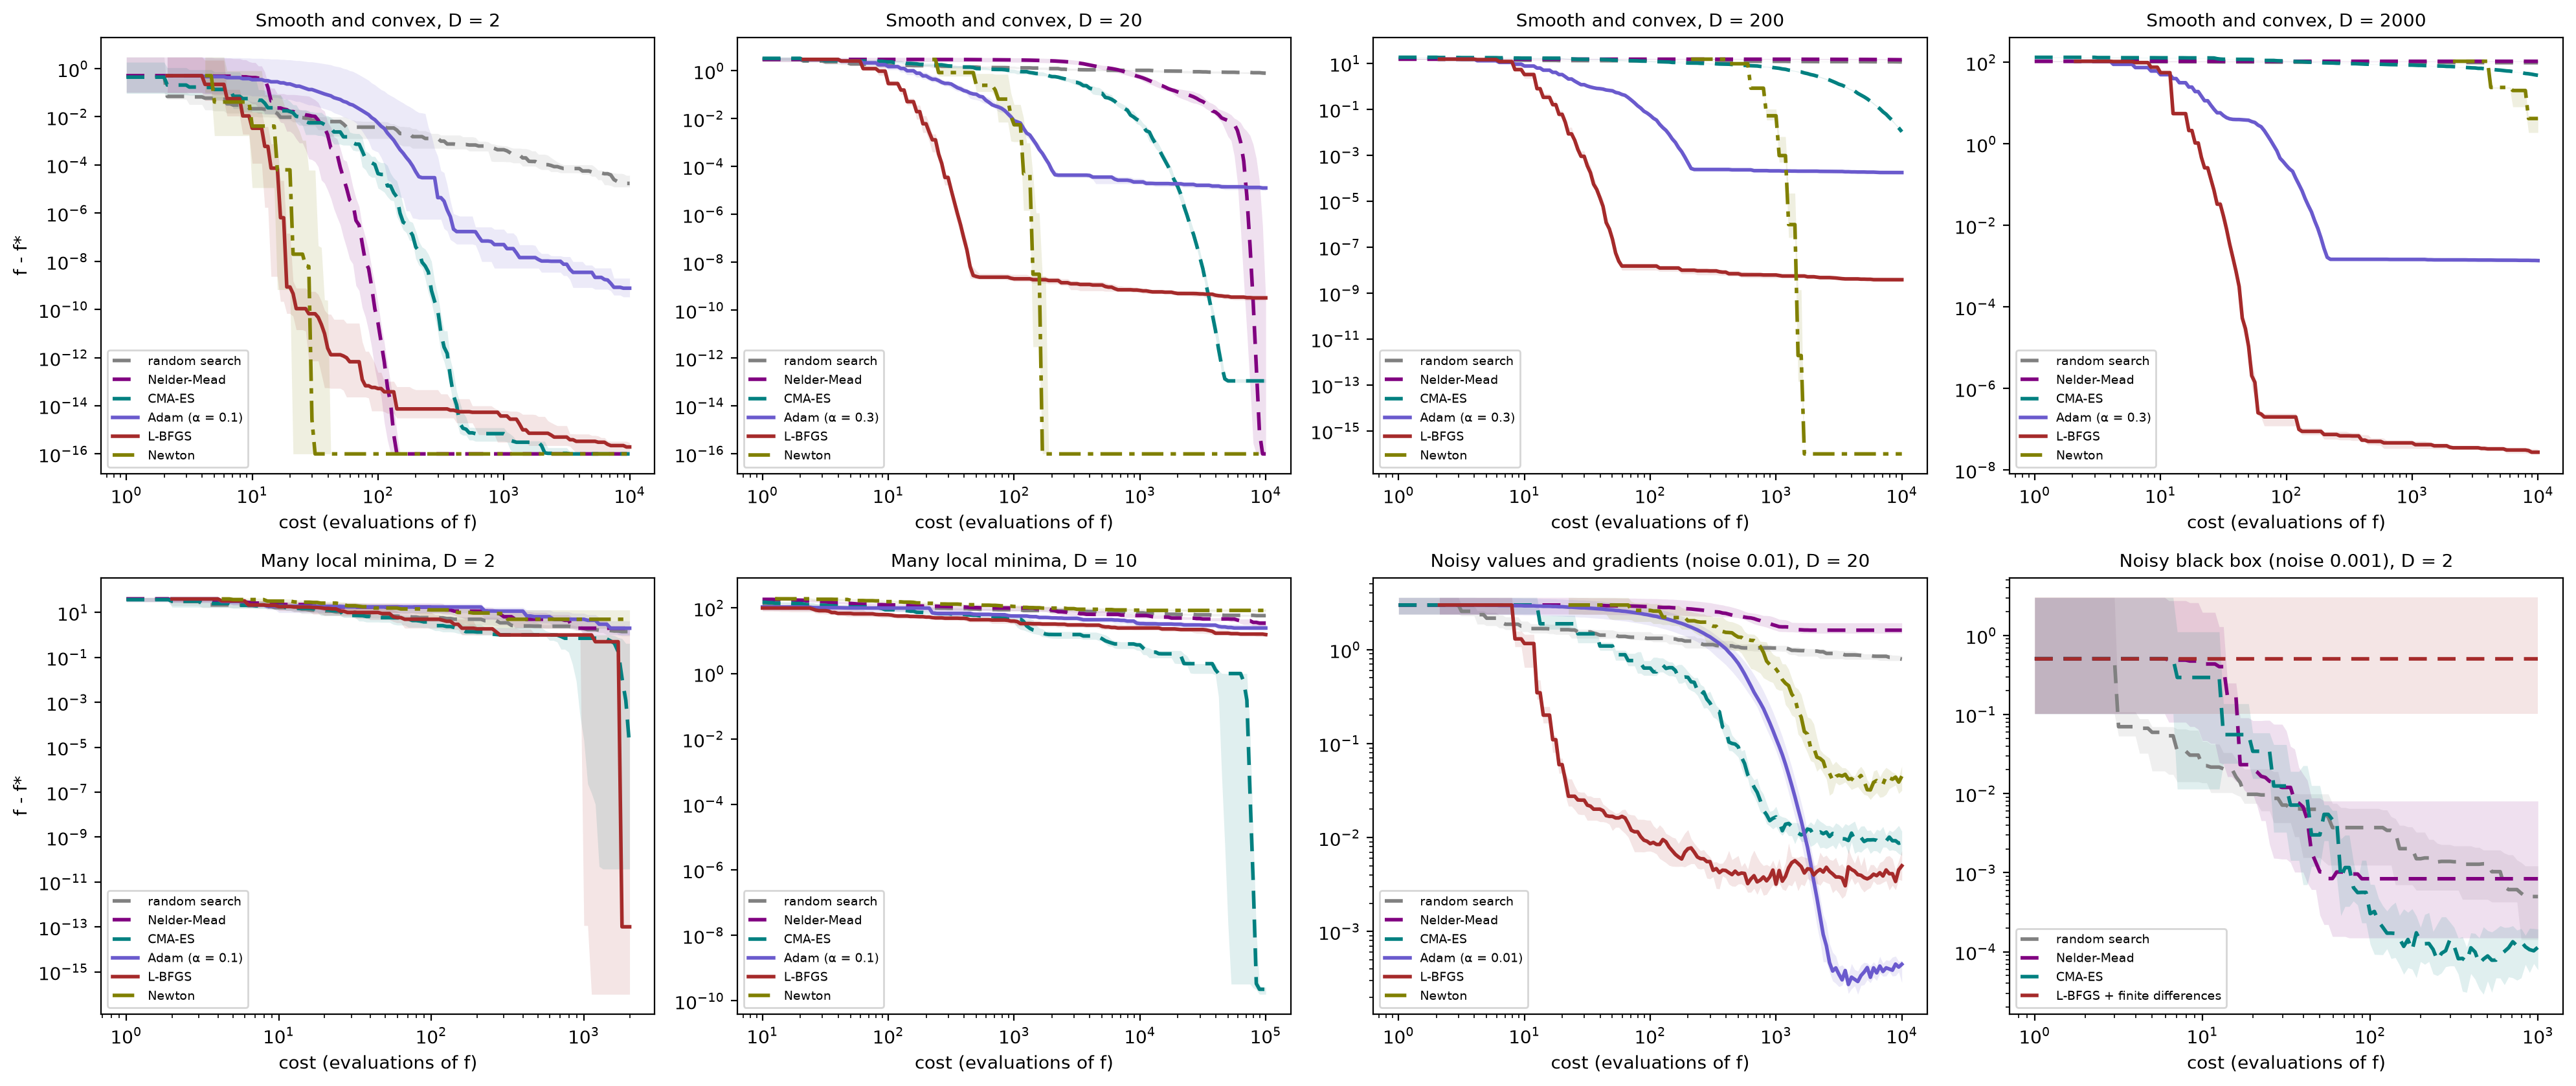

In [19]:
# @title Static version (skipped in the deck): what GitHub, nbviewer and a PDF export show
_ls = {"dash": (0, (5, 3)), "solid": "-", "dashdot": (0, (6, 2, 1.5, 2))}
fig_bench, axs = plt.subplots(2, 4, figsize=(20, 8.5))
for ax, (sc, name) in zip(axs.ravel(), [(k, n) for _, opts in _bench_view["groups"] for n, k in opts]):
    b = bench[sc]
    items = [(lab, q, b["grid"], False) for lab, q in b["curves"].items()]
    if sc == "minibatch":
        items += [("full batch: " + lab, q, bench["fullbatch"]["grid"], True) for lab, q in bench["fullbatch"]["curves"].items()]
    for lab, q, grid, full in items:
        col, sty = _bench_style[lab.replace("full batch: ", "").split(" (α")[0]]
        q = np.array([[np.nan if v is None else v for v in row] for row in q])
        ax.plot(grid, q[1], color=col, ls=":" if full else _ls[sty], lw=1.2 if full else 2, alpha=0.6 if full else 1, label=lab)
        if not full:
            ax.fill_between(grid, q[0], q[2], color=col, alpha=0.12, lw=0)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(b["title"], fontsize=10); ax.set_xlabel("cost (evaluations of f)")
    ax.legend(fontsize=7, loc="lower left")
for ax in axs[:, 0]:
    ax.set_ylabel("f - f*")
fig_bench.tight_layout()
plt.close(fig_bench)
fig_bench

#### Note: how the benchmark was run

This is anecdotal evidence, on purpose small: seven optimizers, ten settings, 20 repetitions each (10 at $D = 2000$, 5 for the full batch). It shows *where* each family shines, not a ranking. Serious benchmarks use hundreds of functions and report the fraction of problems solved against the budget (for example the COCO platform: N. Hansen et al., *COCO: a platform for comparing continuous optimizers in a black-box setting*, Optimization Methods and Software 36, 2021).

* **The problems.**
  * *Smooth*: the mean negative log-likelihood of logistic regression with a small Gaussian prior ($\lambda = 0.01$), on $N = 1000$ points whose features are correlated and differ in scale by a factor of 10. Convex, one minimum.
  * *Many local minima*: Rastrigin, $f(\mathbf{x}) = 10D + \sum_i \left(x_i^2 - 10\cos 2\pi x_i\right)$ on $[-5.12, 5.12]^D$: a bowl covered with bumps, about $11^D$ local minima, the global one at the origin. We count a run as a success when it ends below $f = 10^{-3}$.
  * *Noisy gradients*: the smooth problem with $D = 20$, where every value of $f$, every component of the gradient and every entry of the Hessian comes back with additive Gaussian noise of standard deviation $0.01$. Without the noise, it is the $D = 20$ problem of the "Dimension" group.
  * *Minibatches* (not in the plot): the smooth problem with $N = 100\,000$ and $D = 20$, where every evaluation of $f$ or of the gradient uses a random subset of 32 points (it costs $32/N$ units). The budget is 10 passes over the data. See the lessons below.
  * *Noisy black box*: the smooth problem with $D = 2$, observed with additive Gaussian noise of standard deviation $10^{-3}$, like a simulation with a tolerance or a physical experiment.
* **The cost.** One unit is one evaluation of $f$ on the full data. A gradient costs one more unit (reverse mode, this lecture). A Hessian costs $D$ more ($D$ Hessian-vector products); Newton's linear solve is not charged, which favors Newton.
* **What is recorded.** The true $f - f^*$ of the point the optimizer would return: the best point seen, on the deterministic problems; on the noisy ones the optimizer cannot know the best point, so we record its own recommendation (its current iterate, its mean, or its best noisy value).
* **The optimizers.** Every optimizer restarts from a new random point when it stops, until the budget is spent.
  * Random search, Nelder-Mead and L-BFGS-B (with the exact gradient, or with forward finite differences) are SciPy's, as in Lecture 26.
  * CMA-ES is written in the cell above, following Hansen's tutorial (arXiv:1604.00772), with the usual restart rule that doubles the population each time (IPOP).
  * Newton uses a backtracking line search and stops when the Hessian is not positive definite.
  * Adam uses the defaults of Lecture 27, and gets the best of four step sizes ($10^{-3}$, $10^{-2}$, $10^{-1}$, $0.3$) in each problem: tuning that the others did not get.

Change the problems, the budget or the noise in the code cell above (and delete `optimizer_benchmark.json`) to run your own: the whole benchmark takes about 15 minutes on 16 cores.

### Note: Lessons from this simple benchmark

Each lesson matches a group of buttons in the interactive plot above. The numbers are medians over the repetitions.

**1. Dimension: why first-order optimizers win in machine learning**
* L-BFGS reaches $f - f^* < 10^{-6}$ in 17, 38, 47 and 60 evaluations of $f$ for $D$ = 2, 20, 200 and 2000: its cost barely grows with $D$.
* Nelder-Mead and CMA-ES need 67 and 150 evaluations at $D = 2$, thousands at $D = 20$ (7499 and 2371), and never get there at $D = 200$ within the budget of $10^4$.
* Why: a value of $f$ is one number, while a gradient is $D$ numbers, for the price of about one more value (reverse mode, this lecture). An optimizer that only sees values has to discover the $D$ directions by trial.
* **Takeaway**: when the gradient is available, use it. The advantage grows with $D$, and models have many parameters.

**2. Newton: a Ferrari in a rally race**
* On the road it was built for (smooth, convex, few parameters), it is superb: 21 evaluations at $D = 2$.
* Every step needs the Hessian: $D$ gradients' worth of computation and $D^2$ numbers of memory. It needs 1259 evaluations at $D = 200$, and at $D = 2000$ it is still at $f - f^* = 4.2$ when the budget runs out.
* Memory alone rules it out for large models: $10^6$ parameters give a Hessian of $10^{12}$ numbers (8 TB).
* On bumpy ground it rushes to the nearest local minimum: on Rastrigin with $D = 10$ it ends worse than random search ($f$ = 84 against 58).
* **Takeaway**: Newton for few parameters and a good start. L-BFGS builds an approximation of the curvature from past gradients, almost for free, and keeps most of the benefit.

**3. Noise: why line searches break**
* Compare the button "noisy gradients" with "D = 20" of the Dimension group: the same problem, with and without noise. Without noise, L-BFGS reaches $f - f^* = 3\times10^{-10}$ and Newton the exact minimum. With noise, Adam is the best ($4.5\times10^{-4}$), then L-BFGS ($5.0\times10^{-3}$), CMA-ES ($8.9\times10^{-3}$) and Newton ($4.5\times10^{-2}$).
* Why: the line search of L-BFGS and of Newton compares two values of $f$. Near the minimum the true difference between them is smaller than the noise, so the comparison is a coin toss, the line search fails, and the optimizer stops (SciPy reports a "relative reduction" convergence). Adam never compares values: its momentum averages the noisy gradients, and it moves about $\alpha$ per step.
* On the noisy black box, finite differences divide the noise by $h \approx 10^{-8}$: a noise of $10^{-3}$ becomes an error of about $10^{5}$ in each component of the gradient. L-BFGS + finite differences ends at 0.51, barely moving; CMA-ES reaches $1.1\times10^{-4}$.
* Where do noisy gradients come from? From simulations and experiments, as here, and also from computing the gradient of a loss over a very large dataset on a random subset of the data at every step (a *minibatch*: much cheaper per step, but noisy). We ran that case too ($N = 100\,000$ points, subsets of 32, a budget of 10 passes over the data): Adam reaches $1.4\times10^{-4}$, L-BFGS on the same subsets stalls at $3.7\times10^{-2}$; with all the data at every step, L-BFGS reaches only 0.18 in 10 passes, and Newton cannot finish a single step.
* **Takeaway**: with noisy values or gradients, avoid line searches and finite differences. Prefer optimizers that average (Adam) or that only rank points (CMA-ES).

**4. Gradient-free optimizers still have their place**
* When there is no gradient: a simulation or an experiment, such as the Final Project's.
* When the values are noisy: CMA-ES only needs to know which points are better, not by how much.
* When there are many local minima in few dimensions: on Rastrigin with $D = 2$, 65% of the CMA-ES runs find the global minimum (L-BFGS 55%, Newton 10%, Nelder-Mead 5%); with $D = 10$, 90% of the CMA-ES runs, and none for every other optimizer. Its population samples a region much wider than one bump, and sees the bowl underneath.
* **Takeaway**: CMA-ES or Nelder-Mead in few dimensions (up to a few tens). And with any optimizer: restarts and repetitions (Lecture 26).

This is one small benchmark (see the note above): the lessons hold widely, the exact numbers do not.

### How to choose an optimizer? A rule of thumb

Choosing the right optimizer for the right problem is a difficult task because we don't know the true function we are optimizing.

Still, there are some rules of thumb...

| The problem | First choice | Why |
|:--|:--|:--|
| Many parameters, noisy gradients | Adam | the gradient is cheap at any $D$; momentum averages the noise |
| Smooth and deterministic, gradient available, up to millions of parameters | L-BFGS | curvature from past gradients, almost free |
| Few parameters (up to hundreds), Hessian available | Newton | fewest iterations, if the start is good |
| No gradient, noisy values, or many local minima, in few dimensions | CMA-ES, Nelder-Mead | they only compare values |

And whatever the optimizer: restarts and repetitions to try to get closer to a global optimum (Lecture 26).

## Summary

* Optimizers need gradients. By hand they are exact but do not scale; finite differences cost $D_x + 1$ evaluations and lose half the digits (more in single precision).
* Automatic differentiation splits $f$ into elementary operations, a DAG, and applies the chain rule along it: the derivative adds up the paths, and shared pieces are computed once.
* Forward mode: one sweep per input. Reverse mode: one sweep per output, after a forward sweep that stores the values. For a scalar loss and many parameters, reverse mode: backpropagation.
* Loops and branches are fine: the graph is the one of the run that happened.
* Which optimizer, when: the gradient wins as $D$ grows (it is $D$ numbers for the price of about one $f$); Newton pays $D$ gradients per step; line searches break with noisy evaluations, where Adam copes; gradient-free optimizers keep black boxes, noise and multimodal problems in few dimensions.

## Field guide: what this lecture adds

### Good practices

**4. Fit the model**
- **Get gradients by automatic differentiation when you have the code of the function**: exact up to rounding, for a small multiple of the cost of one evaluation (reverse mode, whatever the number of parameters). Finite differences cost $D_x + 1$ evaluations per gradient and keep about half the digits (fewer in single precision); keep them for black boxes such as a simulation.
- **Choose the optimizer by the dimension, the noise and the landscape**: with many parameters use the gradient (L-BFGS when the evaluations are exact, Adam when they are noisy); Newton only for few parameters, since a Hessian costs $D$ gradients and $D^2$ memory; line searches (L-BFGS, Newton) fail with noisy values, and finite differences amplify the noise. Keep gradient-free optimizers (CMA-ES, Nelder-Mead) for black boxes, noisy values and many local minima in few dimensions.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Have fun!